# TRABAJO PRÁCTICO 03: Árboles de decisión

**Bases de Datos Masivas (11088)** — Departamento de Ciencias Básicas
2° Cuatrimestre 2026 — Universidad Nacional de Luján

**Alumno**: Huici, Nicolas

**Legajo**: 165755

## Ejercicio 1: Entropía y ganancia de información.

Entropía: mide qué tan mezcladas están las clases de un conjunto de datos.
Si todas las filas tienen la misma clase, la entropía es 0, y si hay mitad y mitad en dos clases la entropía es 1.
$$E(S) = -\sum_{i} p_i \log_2(p_i)$$
Donde $p_i$ es la proporción de filas de la clase $i$.
En un problema de clasificación binaria (como es el caso del ejercicio 1), la entropía va a encontrarse siempre entre 0 y 1. Mientras más "mezcladas" las clases mayor la entropía.

Ganancia de información: mide qué tanto baja la entropía al dividir el conjunto según un atributo $A$. Se resta a la entropía original el promedio ponderado de las entropías de cada subconjunto. Es decir cada subconjunto influye en el resultado del cálculo según su tamaño.
$$Gain(S,A) = E(S) - \sum_{v} \frac{|S_v|}{|S|} E(S_v)$$
El atributo con mayor ganancia se elige como raíz.

ID3. Es un algoritmo recursivo y greedy (elige lo mejor en cada paso, sin volver atrás):

1. Si todas las filas tienen la misma clase, se crea una hoja con esa clase.
2. Si no quedan atributos, se crea una hoja con la clase mayoritaria.
3. Si no, se elige el atributo de mayor ganancia, se crea un nodo y por cada valor del atributo se repite el proceso con el subconjunto correspondiente, sin ese atributo.

In [1]:
#Imports y carga de datos
import pandas as pd
import numpy as np

df = pd.read_csv("data/parcial.csv")
df

,ASISTENCIA,TPS,TRABAJA,MODALIDAD,APRUEBA
0,alta,completos,no,presencial,si
1,alta,parciales,si,virtual,si
2,alta,completos,si,presencial,si
3,alta,parciales,no,virtual,si
4,baja,completos,no,presencial,no
5,baja,parciales,si,presencial,no
6,baja,completos,si,virtual,no
7,baja,parciales,no,virtual,no
8,media,completos,si,presencial,si
9,media,completos,no,virtual,si


In [2]:
# Definición de la función de entropía
def entropia(y):
    # y es una columna (Series) con las clases
    proporciones = y.value_counts(normalize=True)
    productos_entropia = proporciones * np.log2(proporciones)
    return max(0.0, -(productos_entropia).sum())

print("Entropía de APRUEBA:", round(entropia(df["APRUEBA"]), 4))

Entropía de APRUEBA: 0.9852


In [3]:
# Función de ganancia de información
def ganancia_informacion(df, atributo, clase):
    entropia_total = entropia(df[clase])
    n = len(df)
    entropia_ponderada = 0
    for valor, subconjunto in df.groupby(atributo):
        peso = len(subconjunto) / n
        entropia_ponderada += peso * entropia(subconjunto[clase])
    return entropia_total - entropia_ponderada

In [4]:
# Ganancia de cada atributo en la raíz
atributos = ["ASISTENCIA", "TPS", "TRABAJA", "MODALIDAD"]
for a in atributos:
    print(a, round(ganancia_informacion(df, a, "APRUEBA"), 4))

ASISTENCIA 0.5917
TPS 0.0611
TRABAJA 0.0202
MODALIDAD 0.0


In [5]:
# Algorito ID3
def id3(df, clase, atributos):
    y = df[clase]
    
    # ficha del nodo: datos que se calculan siempre
    nodo = {
        "n": len(df),
        "clases": y.value_counts().to_dict(),
        "entropia": entropia(y),
    }
    
    # caso 1: todas las filas tienen la misma clase -> hoja
    if y.nunique() == 1:
        nodo["hoja"] = y.iloc[0]
        return nodo
    
    # caso 2: no quedan atributos -> hoja con la clase mayoritaria
    if len(atributos) == 0:
        nodo["hoja"] = y.mode()[0]
        return nodo
    
    # caso general: elegir el atributo con mayor ganancia
    ganancias = {a: ganancia_informacion(df, a, clase) for a in atributos}
    mejor = max(ganancias, key=ganancias.get)
    
    nodo["atributo"] = mejor
    nodo["ganancias"] = ganancias
    restantes = [a for a in atributos if a != mejor]
    nodo["hijos"] = {valor: id3(sub, clase, restantes)
                     for valor, sub in df.groupby(mejor)}
    return nodo

In [6]:
# Construir e imprimir el árbol
def descripcion(nodo):
    clases = ", ".join(f"{k}: {v}" for k, v in nodo["clases"].items())
    return f"n={nodo['n']} [{clases}] | E={nodo['entropia']:.4f}"

def imprimir_arbol(nodo, prefijo="", etiqueta=None, es_ultimo=True, es_raiz=True):
    if es_raiz:
        conector, nuevo_prefijo = "", ""
    else:
        conector = "└── " if es_ultimo else "├── "
        nuevo_prefijo = prefijo + ("    " if es_ultimo else "│   ")
    
    texto_rama = f"({etiqueta}) " if etiqueta is not None else ""
    
    if "hoja" in nodo:
        print(f"{prefijo}{conector}{texto_rama}HOJA → {nodo['hoja']}  | {descripcion(nodo)}")
        return
    
    gi = nodo["ganancias"][nodo["atributo"]]
    print(f"{prefijo}{conector}{texto_rama}¿{nodo['atributo']}?  | {descripcion(nodo)} | GI={gi:.4f}")
    
    hijos = list(nodo["hijos"].items())
    for i, (valor, hijo) in enumerate(hijos):
        imprimir_arbol(hijo, nuevo_prefijo, valor, i == len(hijos) - 1, False)

atributos = ["ASISTENCIA", "TPS", "TRABAJA", "MODALIDAD"]
arbol = id3(df, "APRUEBA", atributos)
imprimir_arbol(arbol)

¿ASISTENCIA?  | n=14 [si: 8, no: 6] | E=0.9852 | GI=0.5917
├── (alta) HOJA → si  | n=4 [si: 4] | E=0.0000
├── (baja) HOJA → no  | n=4 [no: 4] | E=0.0000
└── (media) ¿TPS?  | n=6 [si: 4, no: 2] | E=0.9183 | GI=0.4591
    ├── (completos) HOJA → si  | n=3 [si: 3] | E=0.0000
    └── (parciales) ¿TRABAJA?  | n=3 [no: 2, si: 1] | E=0.9183 | GI=0.9183
        ├── (no) HOJA → si  | n=1 [si: 1] | E=0.0000
        └── (si) HOJA → no  | n=2 [no: 2] | E=0.0000


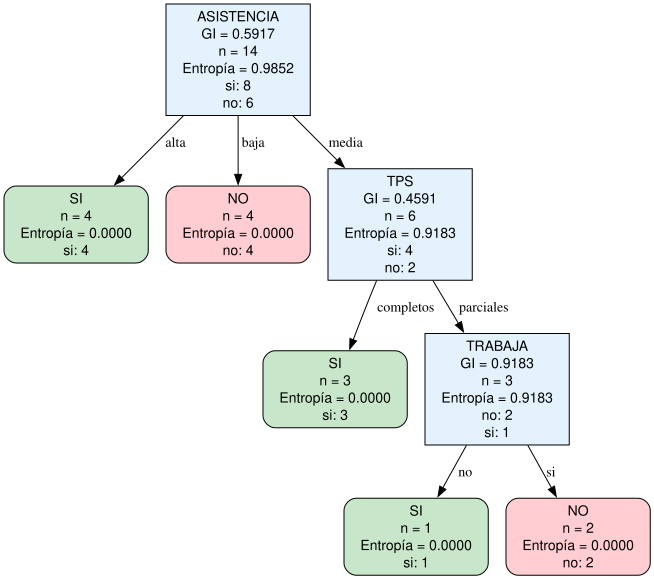

In [7]:

from graphviz import Digraph

def dibujar_arbol(arbol):
    g = Digraph(format="png")
    g.attr("node", fontname="Helvetica")
    contador = [0]  # cada nodo necesita un id único
    
    def agregar(nodo):
        id_nodo = str(contador[0])
        contador[0] += 1
        clases = "\n".join(f"{k}: {v}" for k, v in nodo["clases"].items())
        base = f"n = {nodo['n']}\nEntropía = {nodo['entropia']:.4f}\n{clases}"
        
        if "hoja" in nodo:
            color = "#c8e6c9" if nodo["hoja"] == "si" else "#ffcdd2"
            g.node(id_nodo, f"{nodo['hoja'].upper()}\n{base}",
                   shape="box", style="filled,rounded", fillcolor=color)
        else:
            gi = nodo["ganancias"][nodo["atributo"]]
            g.node(id_nodo, f"{nodo['atributo']}\nGI = {gi:.4f}\n{base}",
                   shape="box", style="filled", fillcolor="#e3f2fd")
            for valor, hijo in nodo["hijos"].items():
                g.edge(id_nodo, agregar(hijo), label=str(valor))
        return id_nodo
    
    agregar(arbol)
    return g

dibujar_arbol(arbol)

### Resultados

El atributo más significativo es 'Asistencia', ya que con asistencia alta o baja se puede determinar si aprueba o no (respectivamente). En cambio con asistencia media debemos observar otras variables. Dentro del subconjunto de observaciones con asistencia media tenemos que la variable 'TPS' es la que aporta la mayor información, siendo que un para un alumno con (asistencia = media, TPS = completos) podemos predecir que va a aprobar directamente. Finalmente para un alumno con (asistencia = media, TPS = parciales) debemos mirar la variable 'Trabaja', quedando (asistencia = media, TPS = parciales, Trabaja = si) como aprobado y (asistencia = media, TPS = parciales, Trabaja = no) se predice como que desaprobará.

## Ejercicio 2: gliomas.csv

### 2.a Utilice la ficha del dataset en el repositorio de la UCI y el Anexo de este enunciado, ¿Cuál es el tema que aborda el dataset?

Sacado del anexo: 'Pacientes con diagnóstico de glioma del proyecto *The Cancer Genome Atlas* (TCGA), con sus datos clínicos y el estado de los 20 genes que mutan con mayor frecuencia en este tipo de tumor.'

En la [ficha del UCI](https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset) podemos encontrar información ampliada del dataset. Según lo que pude llegar a entender sin un trasfondo médico, un **glioma** es el tipo de tumor cerebral más común (según UCI) y pueden ser clasificados como _Low-grade Glioma_ o _Glioblastoma Multiforme_ dependiendo de ciertos factores como la obseración del tejido e imágenes, así como factores moleculares y mutaciones. Realizar test moleculares para el diagnóstico es caro. Por lo que se crea dicho dataset para ayudar a predecir de que tipo de glicoma se trata dependiendo de los 20 genes que mutan con más frecuencia. El proyecto está financiado por _The Cancer Genome Atlas (TCGA) Project – NCI_.

#### En cuanto al dataset en sí (según ficha de UCI)
Las instancias del dataset (objetos de datos) representan registros de pacientes con glioma cerebral. Cada registro está caracterizado por 20 características moleculares (mutada o no_mutada) y 3 características clínicas dependiendo de la demográfica del paciente.
Los datos tienen un preprocesamiento aplicado, para más información sobre esto mirar la ficha del UCI, no me parece extenderme en eso.
Cuenta con 839 instancias con 23 valores cada una.
Por último el dataset no tiene valores vacios.

In [8]:
# Comprobamos que lo que dice la ficha es correcto

df = pd.read_csv("data/gliomas.csv")

print(df.shape)                    # esperado: (839, 24) -> 23 atributos + 1 clase
print(list(df.columns))
print(df["grado"].unique())        # esperado: LGG y GBM

(839, 24)
['sexo', 'edad_diagnostico', 'raza', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA', 'grado']
<ArrowStringArray>
['LGG', 'GBM']
Length: 2, dtype: str


### Conclusiones antes de seguir
Cada instancia (fila) es un paciente con glicoma ya clasificado. Se desea predecir el grado de glicoma de un nuevo paciente (LGG o GBM) utilizando 3 datos clínicos (sexo, edad_diagnostico y raza) y 20 genes (mutado\[1\] o no mutado\[0\]). Por lo que tenemos un problema de clasificación supervisada con dos clases objetivo (LGG/GBM).
Y se desea realizar porque los test moleculares son costosos, por lo que si se logra predecir el grado de manera efectiva se pueden reducir costos

## 2.b. Genere el árbol de decisión que permita clasificar el grado del tumor utilizando un muestreo con proporciones de 80% para entrenamiento y 20% para testeo.

In [9]:
# Propósito: cargar los datos y ver cuántos pacientes hay de cada grado de tumor.
import matplotlib.pyplot as plt

df = pd.read_csv("data/gliomas.csv")

print(f"El dataset tiene {df.shape[0]} pacientes y {df.shape[1]} columnas "
      f"({df.shape[1] - 1} atributos + la clase 'grado').")
print("\nDistribución de la clase a predecir:")
for clase, cant in df["grado"].value_counts().items():
    print(f"  {clase}: {cant} pacientes ({cant / len(df):.1%})")

El dataset tiene 839 pacientes y 24 columnas (23 atributos + la clase 'grado').

Distribución de la clase a predecir:
  LGG: 487 pacientes (58.0%)
  GBM: 352 pacientes (42.0%)


In [17]:
# Propósito: separar los atributos (X) de la clase (y) y convertir 'sexo' y 'raza'
# en columnas numéricas 0/1, porque Scikit-Learn solo trabaja con números.
y = df["grado"]
X = df.drop(columns="grado")

n_antes = X.shape[1]
X = pd.get_dummies(X, columns=["sexo", "raza"], dtype=int)
nuevas = [c for c in X.columns if c.startswith(("sexo_", "raza_"))]

print(f"Atributos antes de codificar: {n_antes} | después: {X.shape[1]}")
print(f"'sexo' y 'raza' se reemplazaron por {len(nuevas)} columnas 0/1:")
for c in nuevas:
    print(f"  - {c}")

Atributos antes de codificar: 23 | después: 27
'sexo' y 'raza' se reemplazaron por 6 columnas 0/1:
  - sexo_Femenino
  - sexo_Masculino
  - raza_Asiática
  - raza_Blanca
  - raza_Indígena americana
  - raza_Negra o afroamericana


Scikit-Learn solo acepta números. get_dummies reemplaza cada columna de texto por una columna 0/1 por cada valor posible. Con raza, que según la ficha tiene 4 categorías (white, black or african american, asian, american indian or alaska native), quedan hasta 4 columnas nuevas. El conteo de columnas final depende de cuántos valores aparezcan en el archivo.

In [18]:
# Propósito: separar los pacientes en entrenamiento (80%) y prueba (20%),
# manteniendo en ambos la misma proporción de LGG y GBM (stratify).
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

resumen = pd.DataFrame({
    "Pacientes": [len(y_train), len(y_test)],
    "% LGG": [(y_train == "LGG").mean() * 100, (y_test == "LGG").mean() * 100],
    "% GBM": [(y_train == "GBM").mean() * 100, (y_test == "GBM").mean() * 100],
}, index=["Entrenamiento (80%)", "Prueba (20%)"]).round(1)
resumen

,Pacientes,% LGG,% GBM
Entrenamiento (80%),671,58.0,42.0
Prueba (20%),168,58.3,41.7


La idea de usar sklearn con stratify=y es que los conjuntos de entrenamiento y prueba (test) tengan una proporción muy parecida en cuanto a sus clases.

In [19]:
# Propósito: entrenar un árbol con criterio de entropía y sin límites de tamaño,
# para tener un punto de partida que luego se intentará mejorar (ejercicio 2c).
from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(criterion="entropy", random_state=42)
modelo.fit(X_train, y_train)

prom = len(X_train) / modelo.get_n_leaves()
print("Árbol entrenado sin restricciones de tamaño:")
print(f"  - Profundidad: {modelo.get_depth()} niveles de preguntas")
print(f"  - Hojas: {modelo.get_n_leaves()}")
print(f"  - Pacientes de entrenamiento por hoja (promedio): {prom:.1f}")

Árbol entrenado sin restricciones de tamaño:
  - Profundidad: 26 niveles de preguntas
  - Hojas: 120
  - Pacientes de entrenamiento por hoja (promedio): 5.6


- criterion="entropy" usa la entropía del ejercicio 1.
- '.fit' hace lo mismo que la función id3: en cada nodo prueba los atributos, elige el de mayor ganancia y divide.
- Se entrena solo con X_train e y_train. Los datos de test los usamos luego para validar. 
- Sin límites, el árbol sigue dividiendo hasta que las hojas quedan puras, así que se espera una profundidad grande.

In [20]:
# Evaluar en train y test
# Propósito: comparar el desempeño en los datos que vio el árbol (entrenamiento)
# con el de datos nuevos (prueba). Una diferencia grande indica sobreajuste.
from sklearn.metrics import accuracy_score

y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Accuracy en entrenamiento: {acc_train:.2%}")
print(f"Accuracy en prueba:        {acc_test:.2%}")
print(f"Diferencia: {(acc_train - acc_test) * 100:.1f} puntos porcentuales")

Accuracy en entrenamiento: 100.00%
Accuracy en prueba:        80.36%
Diferencia: 19.6 puntos porcentuales


### Algunas observaciones
La precisión en 'train' es de 1.0 (perfecta), mientras que en 'test' es de 0.8036, esto indica que el modelo (árbol) memorizó los datos de entrenamiento y presenta sobreajuste, por lo que no se desempeña de la misma manera con los datos de prueba. Diríamos que el modelo presenta sobreajuste, por lo que tiene problemas a la hora de generalizar.

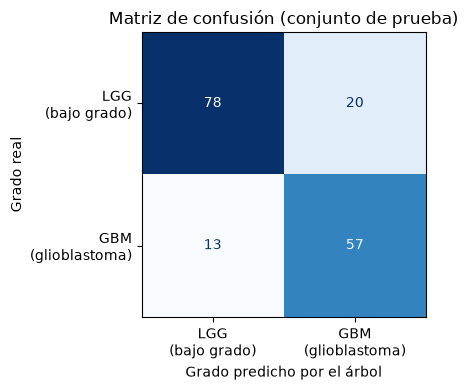

GBM reales: 70. Detectados: 57 (81.4%). Clasificados como LGG: 13 (18.6%) -> error más grave.
LGG reales: 98. Acertados: 78 (79.6%). Clasificados como GBM: 20 (20.4%) -> falsa alarma.
De los 77 pacientes que el árbol llamó GBM, 57 lo eran (74.0%).


In [21]:
# Propósito: ver qué tipos de errores comete el árbol en el conjunto de prueba.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

etiquetas = ["LGG", "GBM"]
cm = confusion_matrix(y_test, y_pred_test, labels=etiquetas)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["LGG\n(bajo grado)", "GBM\n(glioblastoma)"]
                       ).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (conjunto de prueba)")
ax.set_xlabel("Grado predicho por el árbol")
ax.set_ylabel("Grado real")
plt.tight_layout()
plt.show()

lgg_ok, lgg_como_gbm = cm[0]
gbm_como_lgg, gbm_ok = cm[1]
tot_lgg, tot_gbm = cm[0].sum(), cm[1].sum()
pred_gbm = gbm_ok + lgg_como_gbm

print(f"GBM reales: {tot_gbm}. Detectados: {gbm_ok} ({gbm_ok / tot_gbm:.1%}). "
      f"Clasificados como LGG: {gbm_como_lgg} ({gbm_como_lgg / tot_gbm:.1%}) -> error más grave.")
print(f"LGG reales: {tot_lgg}. Acertados: {lgg_ok} ({lgg_ok / tot_lgg:.1%}). "
      f"Clasificados como GBM: {lgg_como_gbm} ({lgg_como_gbm / tot_lgg:.1%}) -> falsa alarma.")
print(f"De los {pred_gbm} pacientes que el árbol llamó GBM, {gbm_ok} lo eran ({gbm_ok / pred_gbm:.1%}).")

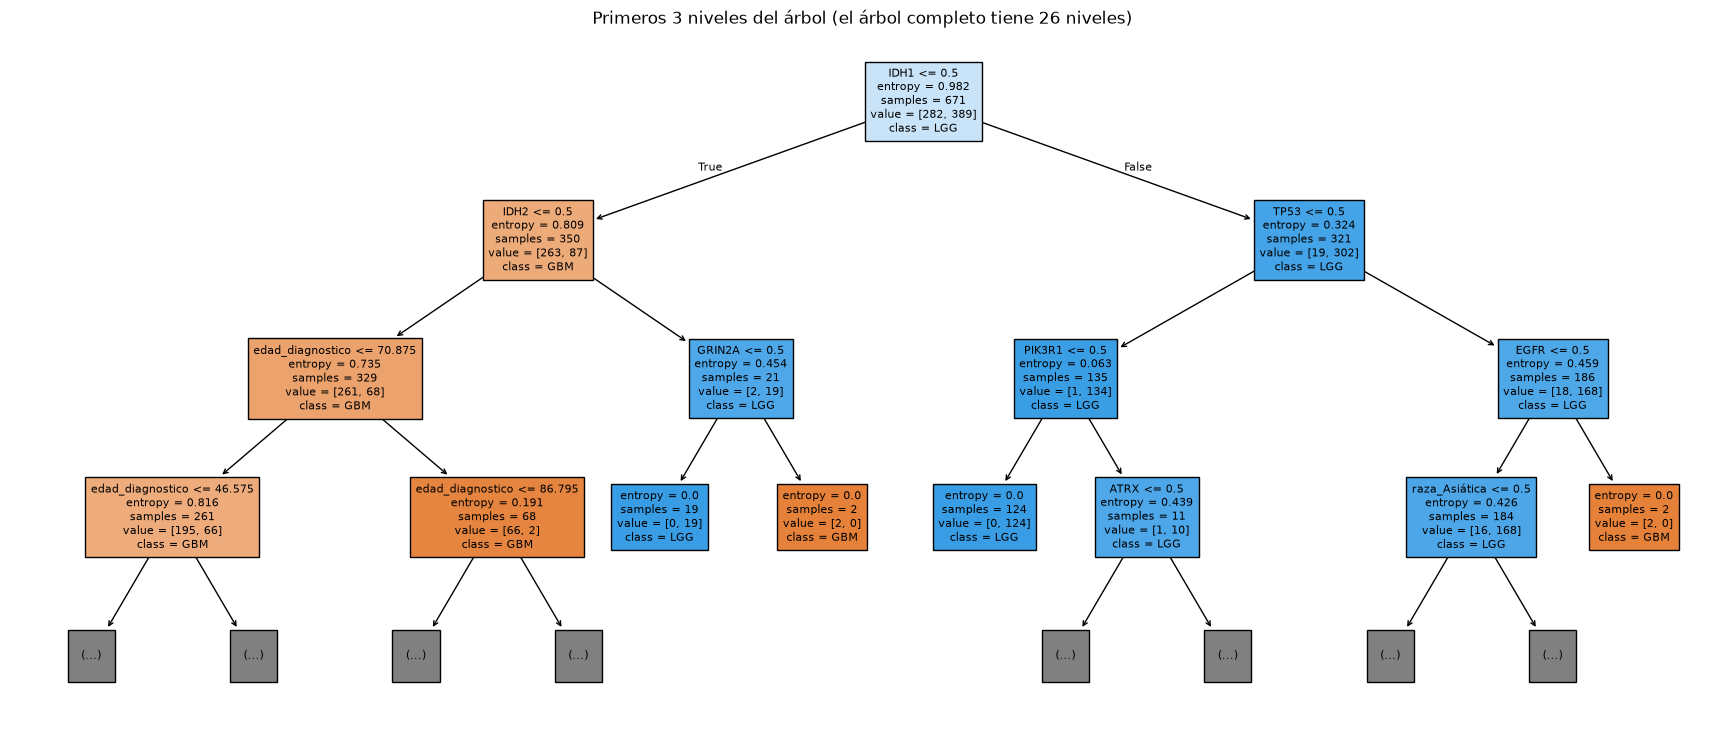

In [22]:
# Propósito: visualizar cómo el árbol toma las primeras decisiones.
# Se muestran solo 3 niveles porque el árbol completo es ilegible.
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 9))
plot_tree(modelo, feature_names=X.columns, class_names=list(modelo.classes_),
          filled=True, max_depth=3, fontsize=8)
plt.title(f"Primeros 3 niveles del árbol (el árbol completo tiene {modelo.get_depth()} niveles)")
plt.show()

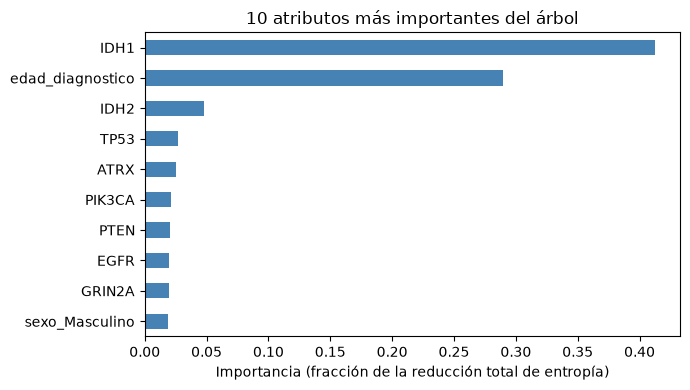

IDH1 y edad_diagnostico juntos explican el 70.2% de la reducción de entropía.
Los 10 atributos mostrados explican el 90.2%; los 17 restantes, el 9.8%.


In [23]:
# Propósito: identificar qué atributos usó más el árbol para reducir la entropía.
imp = (pd.Series(modelo.feature_importances_, index=X.columns)
         .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(7, 4))
imp[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Importancia (fracción de la reducción total de entropía)")
ax.set_title("10 atributos más importantes del árbol")
plt.tight_layout()
plt.show()

print(f"{imp.index[0]} y {imp.index[1]} juntos explican el {imp.iloc[:2].sum():.1%} "
      f"de la reducción de entropía.")
print(f"Los 10 atributos mostrados explican el {imp.sum():.1%}; "
      f"los {len(X.columns) - 10} restantes, el {1 - imp.sum():.1%}.")

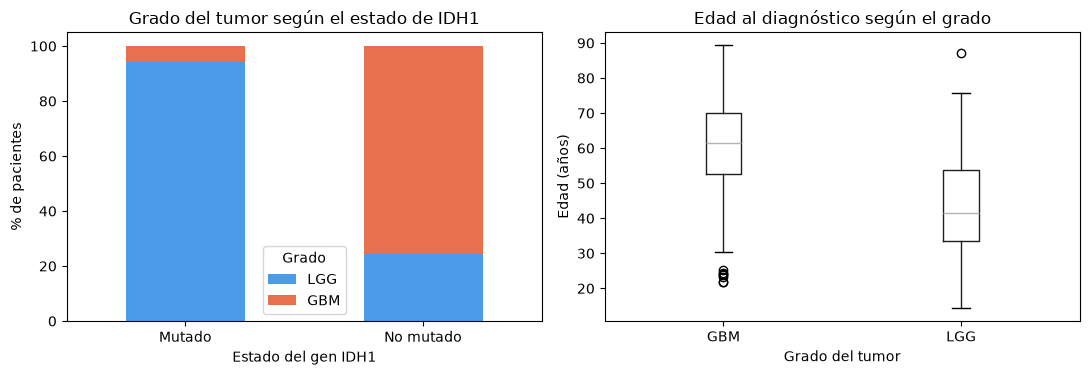

Con IDH1 mutado (404 pacientes): 94.3% son LGG y 5.7% son GBM.
Con IDH1 no mutado (435 pacientes): 24.4% son LGG y 75.6% son GBM.
Edad mediana al diagnóstico: LGG = 41.6 años, GBM = 61.4 años.


In [24]:
# Propósito: la importancia dice cuánto pesa un atributo, no en qué dirección.
# Acá se verifica si IDH1 mutado y la edad se asocian con LGG o con GBM.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

tabla = (pd.crosstab(df["IDH1"].map({0: "No mutado", 1: "Mutado"}), df["grado"],
                     normalize="index")[["LGG", "GBM"]] * 100)
tabla.plot.bar(stacked=True, ax=axes[0], color=["#4c9be8", "#e8704c"], rot=0)
axes[0].set_title("Grado del tumor según el estado de IDH1")
axes[0].set_xlabel("Estado del gen IDH1")
axes[0].set_ylabel("% de pacientes")
axes[0].legend(title="Grado")

df.boxplot(column="edad_diagnostico", by="grado", ax=axes[1], grid=False)
axes[1].set_title("Edad al diagnóstico según el grado")
axes[1].set_xlabel("Grado del tumor")
axes[1].set_ylabel("Edad (años)")

plt.suptitle("")
plt.tight_layout()
plt.show()

for estado, nombre in [(1, "mutado"), (0, "no mutado")]:
    sub = df[df["IDH1"] == estado]
    print(f"Con IDH1 {nombre} ({len(sub)} pacientes): "
          f"{(sub['grado'] == 'LGG').mean():.1%} son LGG y {(sub['grado'] == 'GBM').mean():.1%} son GBM.")
med = df.groupby("grado")["edad_diagnostico"].median()
print(f"Edad mediana al diagnóstico: LGG = {med['LGG']:.1f} años, GBM = {med['GBM']:.1f} años.")

### Resultados
Se tomó el dataset de glicomas.csv y primero se verificó la distribución de la clase a predecir, donde encontramos un 58% de los datos etiquetados como LGG y un 42% etiquetados como GBM, esto es importante para luego cuando dividamos los datos entre test y train verificar que las proporciones dentro de todo se mantienen. Luego separamos los datos en su vector de características y su etiqueta, además como Scikit-Learn solo trabaja con valores numéricos debemos recodificar las variables categóricas, para ello creamos una nueva variable por cada valor y le asignamos un 1 si esa tupla presenta ese valor o 0 de lo contrario.

Una vez los datos están listos y comprendemos la proporción en su distribución de clases objetivo lo que hacemos es separar un conjunto (80%) con el que vamos a entrenar el modelo y otro conjunto (20%) el cuál NO se toca y usaremos para verificar el modelo encontrado. Además verificamos que la distribución en ambos conjuntos se acerquen a la proporción del conjunto original (lo cual ocurre). Con todo esto hecho lo que queda por hacer es entrenar el modelo, para ello lo utilizamos los datos de entrenamiento y un criterio como el del algoritmo ID3, donde se elige cada vez el nodo que aporta más ganancia de información (reduce la entropía) en el estado actual. Cabe recalcar que se genera el árbol completo sin poda (_pruning_) por lo que se espera cierto nivel de sobreajuste a los datos de entrenamiento.

#### Conclusiones
Con el árbol generado ya podemos probarlo con los datos reservados para _test_ y ver cómo se desempeña. Primero probamos la precisión para ver qué tanto sobreajuste presenta, en los datos de entrenamiento tiene una precisión de 1.0 (perfecta), pero en los datos de prueba tiene 0.8036, por lo que podemos decir que el modelo presenta sobreajuste frente los datos de entrenamiento y problemas para generalizar sobre nuevos datos.

En cuanto a la matriz de confusión, se detectó el $\approx$ 81% de los tumores clasificados como GBM realmente como GBM, y un $\approx$ 19% como LGG, en nuesto caso este es el peor caso de error, ya que estaríamos clasificando la variante de tumor más agresivo como la menor agresiva. Esto es a lo que le daría prioridad a mejorar, en cambio el otro error (clasificar un LGG como GBM) sería una falsa alarma, lo cual no es óptimo pero no es tan grave.

Luego presentamos ciertos resultados para ayudarnos a entender mejor el árbol. Los atributos con más peso son IDH1 y edad_diagnostico, que explican el 70% de la reducción de entropía. Donde podemos ver que con IDH1 mutado el 94.3% de pacientes presentan un tumor LGG, mientras que con IDH1 no mutado el 75.6% son GBM.
Además los pacientes con tumor de tipo GBM tienen una mediana de edad mayor a los que presentan un tumor LGG (casi 20 años de diferencia).

Con todo esto en cuenta creo que estamos listos para proceder con el punto 2.c

### 2.c. Explore la solución dada y las posibles configuraciones para obtener un nuevo árbol que clasifique “mejor”. Documente las conclusiones.


### Cuándo un árbol es “mejor”
Nos vamos a basar en ciertas métricas para definirlo: sensibilidad sobre GBM (GBM detectados / GBM reales), ya que detectar un tumor GBM real como un LGG debería ser más grave que al revés. Precisión y Diferencia entre train y test, para medir qué tan preciso es sobre los datos de entrenamiento y qué tan bien generaliza sobre nuevos datos respectivamente.

### El conjunto de prueba no se usa para elegir
Las configuraciones se comparan solo con los 671 pacientes de entrenamiento, usando validación cruzada.
El conjunto de prueba se usa una sola vez, al final, con la configuración elegida.
Esto es importante ya que si se usa el conjunto de prueba para ir probando las configuraciones del árbol mientras se va entrenando ese conjunto de prueba pierde el sentido, ya que no clasificaría técnicamente como "datos nuevos".

### Validación cruzada de 5 folds
Los 671 pacientes se reparten en 5 grupos de ≈ 134 (671 / 5 = 134.2).
Se entrena con 4 grupos (≈ 537 pacientes) y se valida con el grupo restante.
Se repite 5 veces, rotando el grupo de validación, y se promedian los 5 resultados.

Así cada paciente se usa para validar exactamente una vez.

### Hiperparámetros que se van a explorar
- max_depth: Cantidad máxima de preguntas encadenadas. Con 3, como mucho 2³ = 8 hojas.
- min_samples_leaf: Mínimo de pacientes en cada hoja.
- min_samples_split: Mínimo de pacientes para que un nodo pueda dividirse.
- class_weight: Cuánto pesa cada clase al entrenar.


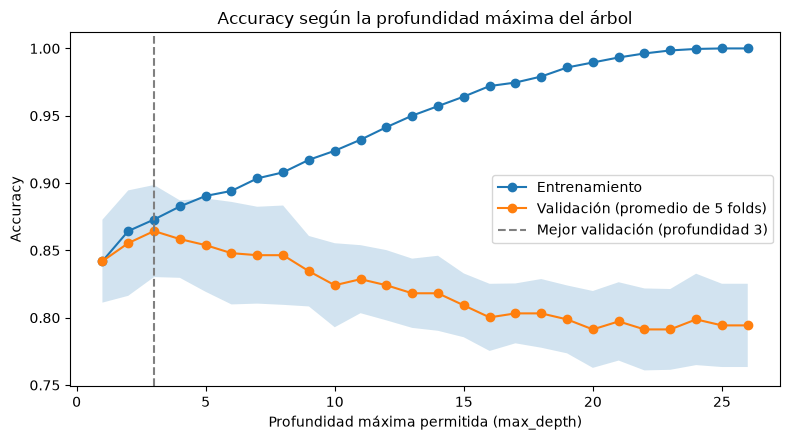

Mayor accuracy de validación: 86.44% (± 3.42%) con max_depth = 3.
Árbol más simple dentro de una desviación estándar del mejor: max_depth = 1 (accuracy de validación 84.20%).
Sin límite (profundidad 26): accuracy de validación 79.43%, accuracy de entrenamiento 100.00%.


In [26]:
# Propósito: ver cómo cambia el desempeño al limitar la profundidad máxima del árbol.
# Se usa validación cruzada de 5 folds SOLO sobre el conjunto de entrenamiento,
# para no tocar el conjunto de prueba hasta la evaluación final.
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
profundidades = range(1, modelo.get_depth() + 1)

filas = []
for p in profundidades:
    m = DecisionTreeClassifier(criterion="entropy", max_depth=p, random_state=42)
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    filas.append({"max_depth": p,
                  "acc_train": r["train_score"].mean(),
                  "acc_val": r["test_score"].mean(),
                  "desvio_val": r["test_score"].std()})
tabla = pd.DataFrame(filas).set_index("max_depth")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla.index, tabla["acc_train"], marker="o", label="Entrenamiento")
ax.plot(tabla.index, tabla["acc_val"], marker="o", label="Validación (promedio de 5 folds)")
ax.fill_between(tabla.index, tabla["acc_val"] - tabla["desvio_val"],
                tabla["acc_val"] + tabla["desvio_val"], alpha=0.2)
mejor = tabla["acc_val"].idxmax()
ax.axvline(mejor, color="gray", linestyle="--", label=f"Mejor validación (profundidad {mejor})")
ax.set_xlabel("Profundidad máxima permitida (max_depth)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy según la profundidad máxima del árbol")
ax.legend()
plt.tight_layout()
plt.show()

mejor_acc, mejor_std = tabla.loc[mejor, "acc_val"], tabla.loc[mejor, "desvio_val"]
simple = tabla[tabla["acc_val"] >= mejor_acc - mejor_std].index.min()
print(f"Mayor accuracy de validación: {mejor_acc:.2%} (± {mejor_std:.2%}) con max_depth = {mejor}.")
print(f"Árbol más simple dentro de una desviación estándar del mejor: max_depth = {simple} "
      f"(accuracy de validación {tabla.loc[simple, 'acc_val']:.2%}).")
print(f"Sin límite (profundidad {modelo.get_depth()}): accuracy de validación "
      f"{tabla.iloc[-1]['acc_val']:.2%}, accuracy de entrenamiento {tabla.iloc[-1]['acc_train']:.2%}.")

,Accuracy (%),Recall GBM (%),Precision GBM (%)
max_depth,,,
1,84.2,93.3,75.4
2,85.5,92.9,77.8
3,86.4,92.6,79.2
4,85.8,90.4,79.3
5,85.4,91.1,78.3
6,84.8,90.4,77.7
7,84.6,89.4,78.0
8,84.6,88.7,78.4
9,83.5,87.9,76.6


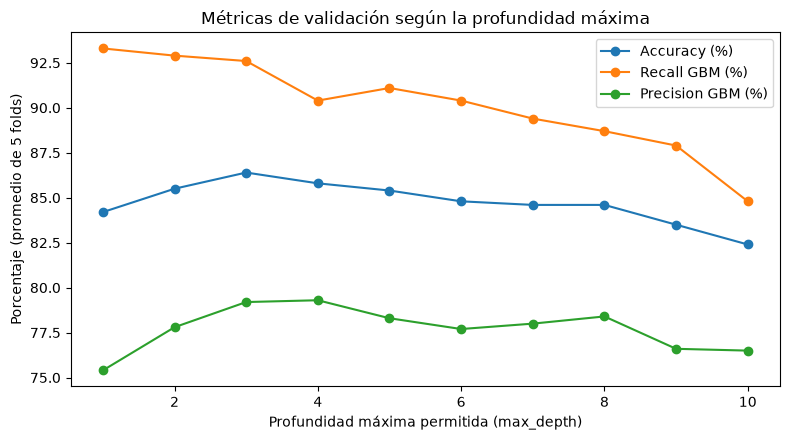

Mayor recall de GBM en validación: 93.3% con max_depth = 1.


In [27]:
# Propósito: comparar accuracy, recall de GBM y precision de GBM para cada profundidad máxima.
# La accuracy sola no distingue qué tipo de error se comete; el recall de GBM mide
# cuántos tumores agresivos se detectan, y la precision de GBM cuántas alarmas son reales.
# Todo con validación cruzada de 5 folds sobre el conjunto de entrenamiento.
from sklearn.metrics import make_scorer, recall_score, precision_score
from IPython.display import display

metricas = {"accuracy": "accuracy",
            "recall_GBM": make_scorer(recall_score, pos_label="GBM"),
            "precision_GBM": make_scorer(precision_score, pos_label="GBM")}

filas = []
for p in range(1, 11):
    m = DecisionTreeClassifier(criterion="entropy", max_depth=p, random_state=42)
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=metricas)
    filas.append({"max_depth": p,
                  "Accuracy (%)": r["test_accuracy"].mean() * 100,
                  "Recall GBM (%)": r["test_recall_GBM"].mean() * 100,
                  "Precision GBM (%)": r["test_precision_GBM"].mean() * 100})
tabla_m = pd.DataFrame(filas).set_index("max_depth").round(1)
display(tabla_m)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col in tabla_m.columns:
    ax.plot(tabla_m.index, tabla_m[col], marker="o", label=col)
ax.set_xlabel("Profundidad máxima permitida (max_depth)")
ax.set_ylabel("Porcentaje (promedio de 5 folds)")
ax.set_title("Métricas de validación según la profundidad máxima")
ax.legend()
plt.tight_layout()
plt.show()

mejor_recall = tabla_m["Recall GBM (%)"].idxmax()
print(f"Mayor recall de GBM en validación: {tabla_m.loc[mejor_recall, 'Recall GBM (%)']:.1f}% "
      f"con max_depth = {mejor_recall}.")

In [28]:
# Propósito: probar combinaciones de hiperparámetros con validación cruzada de 5 folds
# (solo sobre entrenamiento) y ordenarlas por F2 de GBM, que prioriza detectar los GBM.
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import fbeta_score

grilla = {"max_depth": [2, 3, 4, 5, 6, 8],
          "min_samples_leaf": [1, 5, 10, 20, 30],
          "class_weight": [None, "balanced"]}

metricas = {"accuracy": "accuracy",
            "recall_GBM": make_scorer(recall_score, pos_label="GBM"),
            "precision_GBM": make_scorer(precision_score, pos_label="GBM"),
            "F2_GBM": make_scorer(fbeta_score, beta=2, pos_label="GBM")}

busqueda = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=42),
                        grilla, scoring=metricas, refit="F2_GBM", cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)

res = pd.DataFrame(busqueda.cv_results_)
tabla_g = pd.DataFrame({
    "max_depth": res["param_max_depth"],
    "min_samples_leaf": res["param_min_samples_leaf"],
    "class_weight": res["param_class_weight"].astype(str).replace({"None": "ninguno"}),
    "Accuracy (%)": res["mean_test_accuracy"] * 100,
    "Recall GBM (%)": res["mean_test_recall_GBM"] * 100,
    "Precision GBM (%)": res["mean_test_precision_GBM"] * 100,
    "F2 GBM (%)": res["mean_test_F2_GBM"] * 100,
}).sort_values("F2 GBM (%)", ascending=False).head(10).round(1).reset_index(drop=True)
tabla_g.index = tabla_g.index + 1

print(f"Se probaron {len(res)} configuraciones. Las 10 mejores según F2 de GBM (validación cruzada):")
display(tabla_g)
print(f"Primera de la lista: {busqueda.best_params_} "
      f"(F2 de validación = {busqueda.best_score_:.1%}).")

Se probaron 60 configuraciones. Las 10 mejores según F2 de GBM (validación cruzada):


,max_depth,min_samples_leaf,class_weight,Accuracy (%),Recall GBM (%),Precision GBM (%),F2 GBM (%)
1,3,5,NaN,86.7,92.6,79.7,89.6
2,3,10,NaN,86.7,92.6,79.7,89.6
3,4,10,balanced,86.7,92.6,79.7,89.6
4,3,10,balanced,86.7,92.6,79.7,89.6
5,3,5,balanced,86.7,92.6,79.7,89.6
6,5,5,NaN,87.0,92.2,80.4,89.5
7,3,1,balanced,86.4,92.6,79.2,89.5
8,3,1,NaN,86.4,92.6,79.2,89.5
9,5,5,balanced,86.9,92.2,80.2,89.4
10,2,10,NaN,85.7,92.9,78.0,89.4


Primera de la lista: {'class_weight': None, 'max_depth': 3, 'min_samples_leaf': 5} (F2 de validación = 89.6%).


In [29]:
# Propósito: comparar los dos criterios de división (entropía y Gini) manteniendo fija
# la configuración elegida (max_depth=3, min_samples_leaf=10), con la misma
# validación cruzada de 5 folds sobre el conjunto de entrenamiento.
filas = []
for criterio in ["entropy", "gini"]:
    m = DecisionTreeClassifier(criterion=criterio, max_depth=3,
                               min_samples_leaf=10, random_state=42)
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=metricas)
    filas.append({"Criterio": criterio,
                  "Accuracy (%)": r["test_accuracy"].mean() * 100,
                  "Recall GBM (%)": r["test_recall_GBM"].mean() * 100,
                  "Precision GBM (%)": r["test_precision_GBM"].mean() * 100,
                  "F2 GBM (%)": r["test_F2_GBM"].mean() * 100})

print("Comparación de criterios con max_depth=3 y min_samples_leaf=10 (validación cruzada):")
display(pd.DataFrame(filas).set_index("Criterio").round(1))

Comparación de criterios con max_depth=3 y min_samples_leaf=10 (validación cruzada):


,Accuracy (%),Recall GBM (%),Precision GBM (%),F2 GBM (%)
Criterio,,,,
entropy,86.7,92.6,79.7,89.6
gini,86.7,92.6,79.7,89.6


,Árbol original (sin límites),"Árbol final (max_depth=3, min_samples_leaf=10)"
Profundidad,26,3
Cantidad de hojas,120,8
Accuracy en entrenamiento,100.0%,86.7%
Accuracy en prueba,80.4%,87.5%
Diferencia train − prueba (puntos),19.6,-0.8
Recall GBM (prueba),81.4%,94.3%
Precision GBM (prueba),74.0%,79.5%
F2 GBM (prueba),79.8%,90.9%


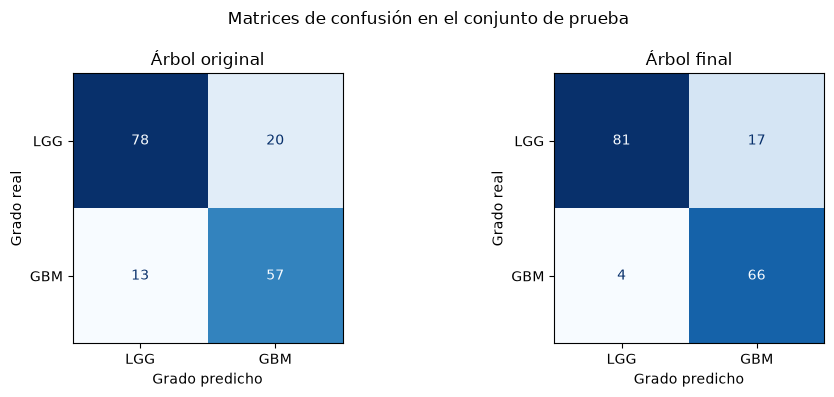

GBM reales en prueba: 70.
GBM detectados:            57 (original) -> 66 (final)
GBM clasificados como LGG: 13 (original) -> 4 (final)   [error más grave]
LGG clasificados como GBM: 20 (original) -> 17 (final)   [falsa alarma]


In [30]:
# Propósito: entrenar el árbol final con la configuración elegida y compararlo con el árbol
# original sobre el conjunto de prueba, que ninguno de los dos vio durante el entrenamiento
# ni durante la elección de hiperparámetros.
from sklearn.metrics import fbeta_score
from IPython.display import display

modelo_final = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                      min_samples_leaf=10, random_state=42)
modelo_final.fit(X_train, y_train)

def resumen(m):
    pred_tr, pred_te = m.predict(X_train), m.predict(X_test)
    acc_tr, acc_te = accuracy_score(y_train, pred_tr), accuracy_score(y_test, pred_te)
    rec = recall_score(y_test, pred_te, pos_label="GBM")
    pre = precision_score(y_test, pred_te, pos_label="GBM")
    f2 = fbeta_score(y_test, pred_te, beta=2, pos_label="GBM")
    return [m.get_depth(), m.get_n_leaves(), f"{acc_tr:.1%}", f"{acc_te:.1%}",
            f"{(acc_tr - acc_te) * 100:.1f}", f"{rec:.1%}", f"{pre:.1%}", f"{f2:.1%}"]

filas = ["Profundidad", "Cantidad de hojas", "Accuracy en entrenamiento", "Accuracy en prueba",
         "Diferencia train − prueba (puntos)", "Recall GBM (prueba)",
         "Precision GBM (prueba)", "F2 GBM (prueba)"]
comparacion = pd.DataFrame({"Árbol original (sin límites)": resumen(modelo),
                            "Árbol final (max_depth=3, min_samples_leaf=10)": resumen(modelo_final)},
                           index=filas)
display(comparacion)

etiquetas = ["LGG", "GBM"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m, titulo in [(axes[0], modelo, "Árbol original"), (axes[1], modelo_final, "Árbol final")]:
    cm = confusion_matrix(y_test, m.predict(X_test), labels=etiquetas)
    ConfusionMatrixDisplay(cm, display_labels=["LGG", "GBM"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo)
    ax.set_xlabel("Grado predicho")
    ax.set_ylabel("Grado real")
plt.suptitle("Matrices de confusión en el conjunto de prueba")
plt.tight_layout()
plt.show()

cm_o = confusion_matrix(y_test, modelo.predict(X_test), labels=etiquetas)
cm_f = confusion_matrix(y_test, modelo_final.predict(X_test), labels=etiquetas)
print(f"GBM reales en prueba: {cm_f[1].sum()}.")
print(f"GBM detectados:            {cm_o[1, 1]} (original) -> {cm_f[1, 1]} (final)")
print(f"GBM clasificados como LGG: {cm_o[1, 0]} (original) -> {cm_f[1, 0]} (final)   [error más grave]")
print(f"LGG clasificados como GBM: {cm_o[0, 1]} (original) -> {cm_f[0, 1]} (final)   [falsa alarma]")

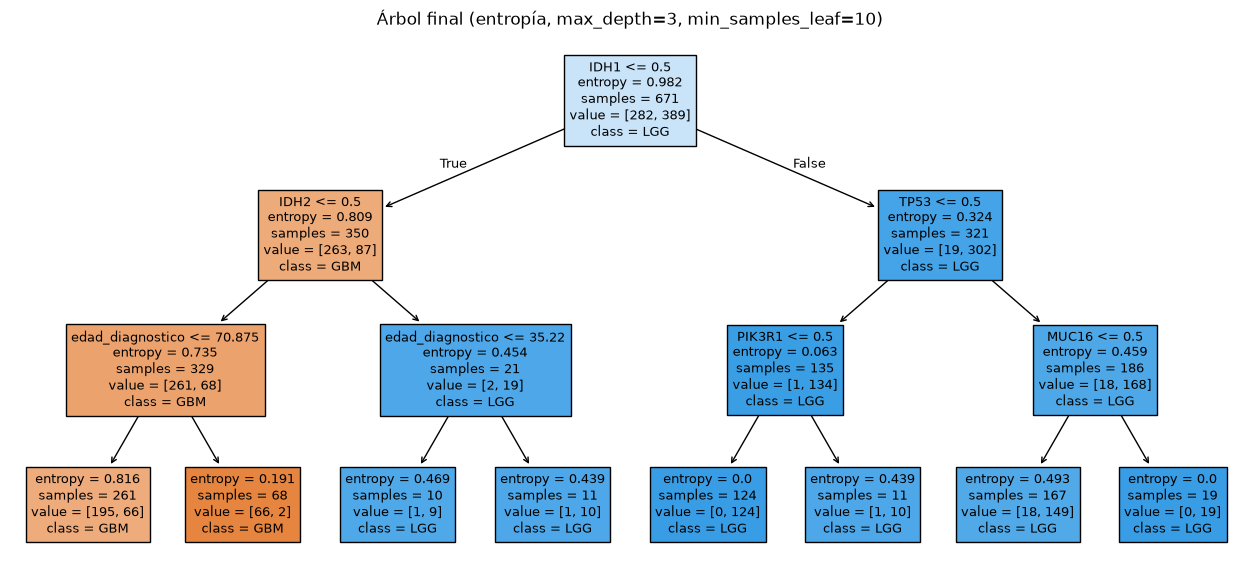

In [31]:
# Propósito: mostrar las reglas completas del árbol final. Con profundidad 3 tiene pocas
# hojas, así que se puede leer entero (a diferencia del árbol original).
plt.figure(figsize=(16, 7))
plot_tree(modelo_final, feature_names=X.columns, class_names=list(modelo_final.classes_),
          filled=True, fontsize=9)
plt.title("Árbol final (entropía, max_depth=3, min_samples_leaf=10)")
plt.show()

In [32]:
# Propósito: comprobar con datos que el tercer nivel del árbol final no modifica ninguna
# predicción, comparándolo con un árbol de profundidad 2 entrenado con los mismos parámetros.
# Es solo una verificación: el árbol elegido sigue siendo el de profundidad 3.
modelo_2 = DecisionTreeClassifier(criterion="entropy", max_depth=2,
                                  min_samples_leaf=10, random_state=42)
modelo_2.fit(X_train, y_train)

igual_tr = (modelo_2.predict(X_train) == modelo_final.predict(X_train)).sum()
igual_te = (modelo_2.predict(X_test) == modelo_final.predict(X_test)).sum()

print("Árboles de profundidad 2 y 3 (mismos demás parámetros) predicen igual en:")
print(f"  - {igual_tr} de {len(X_train)} pacientes de entrenamiento ({igual_tr / len(X_train):.1%})")
print(f"  - {igual_te} de {len(X_test)} pacientes de prueba ({igual_te / len(X_test):.1%})")
print(f"Hojas: profundidad 2 = {modelo_2.get_n_leaves()}, profundidad 3 = {modelo_final.get_n_leaves()}.")

Árboles de profundidad 2 y 3 (mismos demás parámetros) predicen igual en:
  - 671 de 671 pacientes de entrenamiento (100.0%)
  - 168 de 168 pacientes de prueba (100.0%)
Hojas: profundidad 2 = 4, profundidad 3 = 8.


### Conclusiones
Lo que se realizó fue un intento de mejora de predicción sobre el modelo anterior, no se pretende que este nuevo árbol sea el óptimo, ni el "mejor", ya que para hacer esto habría que calibrarlo mejor y considerar varios factores extras que me parece que exceden el alcance del ejercicio para mi nivel. Además creo que dado el tiempo limitado, hubiera creado más confusión. Por lo que se prioriza un mejor entendimiento de lo que está pasando, aunque esto sacrifique desempeño. Sin embargo, dicho todo esto, estoy satisfecho con el resultado y creo que el árbol conseguido finalmente se desempeña bastante mejor que el árbol original.

#### Lo que se exploró
Se hizo una hipercalibración del árbol original modificando un conjunto reducido de parámetros que incluye: profundidad máxima, mínimo de pacientes por hoja, peso de clases y criterio de división. Todo esto utilizando una validación K-Fold con $K = 5$, sobre el conjunto de entrenamiento (sin tocar para nada el conjunto de pruebas). La elección del K fue completamente arbitrario basado en lo visto en la teórica que nombra $K = 5$ y $K = 10$ como los 'K mágicos'.

### Criterio de “mejor”
Este concepto es **muy** importante para lo que se hizo y voy a tratar de explicar lo mejor que pueda el por qué. Para decidir si un árbol es "mejor" que el otro decidimos tomar como medidas de comparación la sensibilidad (_recall_) de GBM como prioridad, y la precisión (_accuracy_) como indicador secundario. Por eso usamos F2 en lugar de F1 para evaluar, ya que F2 le da más importancia a la pérdida de recall que de precisión.

Cuando digo que este concepto es muy importante quiero decir que dependiendo de los indicadores que tomemos para decidir que árbol es mejor vamos a terminar con un árbol u otro. En mi caso prioricé la sensibilidad o recall ya que me parece importante darle más importancia a los falsos negativos respecto de GBM que respecto de LGG. Si el modelo clasifica un tumor que realmente es LGG como GBM ocasionaría una falsa alarma, lo cuál no es óptimo si ocurre de manera sistemática, pero en casos aislados me parece más tolerable. En cambio si el modelo clasifica un tumor que realmente es GBM como LGG le está quitando importancia a un tumor que se considera grave, por lo que me parece más importante evitar que esto ocurra aunque se trate de casos aislados. Y creo que el árbol conseguido refleja justamente eso.

### El efecto de cada parámetro
- max_depth fue el que más importó (curva de sobreajuste).
- min_samples_leaf aportó poco con profundidad 3.
- class_weight no cambió nada.
- Entropía y Gini dieron resultados idénticos.

### Resultado final
El árbol original tenía una precisión perfecta en entrenamiento y luego bajaba casi un 20% en test, el nuevo árbol se comporta de manera parecida en ambos conjuntos y aumenta un 7% la predicción en test respecto al original, lo que ya de por si es un buen indicio. Además la sensibilidad (_recall_) respecto a la clase GBM aumentó un 13% y el indíce F2 un 10%. 

Todo esto indica que el árbol generaliza mejor, que no simplemente memoriza los datos de entrenamiento, y además clasifica considerablemente mejor los casos de tumor GBM, lo cual era lo buscado. 

En cuanto a las interpretaciones que podemos hacer mirando el árbol final podemos decid que se reduce a “IDH1 e IDH2 no mutados implica GBM”, y la edad afina la confianza pero no el diagnóstico. (mirando los nodos pintados de naranja).

### Limitaciones a considerar
- El conjunto de prueba tiene 168 pacientes y solo 70 GBM, así que cada GBM mueve el recall 1.4 puntos.
- Se usó una única partición 80/20 (random_state=42), y otra partición podría dar números algo distintos.

## Ejercicio 3: asalariados_eph.csv

### 3.a. Utilice el Anexo y el registro de diseño de la EPH para entender los datos, ¿Cuál es el tema que aborda el dataset?
Asalariados (obreros o empleados, incluido el servicio doméstico) relevados por la Encuesta Permanente de Hogares en los 32 aglomerados urbanos que cubre la base durante el primer trimestre de 2026. Cada fila es una persona encuestada; las filas no están expandidas por el ponderador, por lo que las proporciones del dataset no son estimaciones poblacionales.

In [33]:
# Propósito: cargar el dataset de asalariados de la EPH y armar un diccionario de variables:
# qué mide cada columna, a qué variable de la EPH corresponde, de qué tipo es,
# cuántos valores distintos tiene y qué porcentaje de celdas vacías.
import pandas as pd
from IPython.display import display

df_eph = pd.read_csv("data/asalariados_eph.csv")
print(f"El dataset tiene {df_eph.shape[0]:,} asalariados (filas) y {df_eph.shape[1]} columnas.".replace(",", "."))

diccionario = {
    "region": ("Región estadística del aglomerado", "REGION", "categórica"),
    "sexo": ("Sexo de la persona", "CH04", "categórica"),
    "edad": ("Edad en años cumplidos", "CH06", "numérica"),
    "nivel_educativo": ("Máximo nivel educativo alcanzado", "NIVEL_ED", "ordinal"),
    "sector": ("Tipo de lugar de trabajo: estatal, privado u otro", "PP04A", "categórica"),
    "rama": ("Rama de actividad del establecimiento (agrupada)", "PP04B_COD", "categórica"),
    "calificacion": ("Calificación de la ocupación: profesional, técnica, operativa o no calificada", "PP04D_COD", "ordinal"),
    "tamanio_establecimiento": ("Cantidad de personas que trabajan en el establecimiento, en tramos del 1 al 12", "PP04C", "ordinal"),
    "lugar_trabajo": ("Dónde realiza principalmente sus tareas", "PP04G", "categórica"),
    "antiguedad": ("Tiempo continuo en ese empleo", "PP07A", "ordinal"),
    "empleo_temporario": ("Si el empleo tiene tiempo de finalización (si/no)", "PP07C", "binaria"),
    "horas_semanales": ("Horas trabajadas en la semana en la ocupación principal", "PP3E_TOT", "numérica"),
    "ingreso_mensual": ("Ingreso mensual de la ocupación principal, en pesos corrientes", "P21", "numérica"),
    "informal": ("CLASE: 'si' = sin descuento jubilatorio por ese trabajo; 'no' = con descuento", "PP07H", "binaria (clase)"),
}

tabla = pd.DataFrame({
    "Qué mide": [diccionario[c][0] for c in df_eph.columns],
    "Variable EPH": [diccionario[c][1] for c in df_eph.columns],
    "Tipo": [diccionario[c][2] for c in df_eph.columns],
    "Valores distintos": [df_eph[c].nunique() for c in df_eph.columns],
    "% de celdas vacías": [round(df_eph[c].isna().mean() * 100, 1) for c in df_eph.columns],
}, index=df_eph.columns)
display(tabla)

con_vacios = tabla[tabla["% de celdas vacías"] > 0]
print("\nColumnas con celdas vacías (sin dato en la fuente):")
for col, fila in con_vacios.iterrows():
    print(f"  - {col}: {fila['% de celdas vacías']}% de las filas")

El dataset tiene 13.938 asalariados (filas) y 14 columnas.


,Qué mide,Variable EPH,Tipo,Valores distintos,% de celdas vacías
region,Región estadística del aglomerado,REGION,categórica,6,0.0
sexo,Sexo de la persona,CH04,categórica,2,0.0
edad,Edad en años cumplidos,CH06,numérica,75,0.0
nivel_educativo,Máximo nivel educativo alcanzado,NIVEL_ED,ordinal,7,0.0
sector,"Tipo de lugar de trabajo: estatal, privado u otro",PP04A,categórica,3,0.0
rama,Rama de actividad del establecimiento (agrupada),PP04B_COD,categórica,15,0.0
calificacion,"Calificación de la ocupación: profesional, téc...",PP04D_COD,ordinal,4,0.1
tamanio_establecimiento,Cantidad de personas que trabajan en el establ...,PP04C,ordinal,12,27.8
lugar_trabajo,Dónde realiza principalmente sus tareas,PP04G,categórica,9,9.4
antiguedad,Tiempo continuo en ese empleo,PP07A,ordinal,6,10.1



Columnas con celdas vacías (sin dato en la fuente):
  - calificacion: 0.1% de las filas
  - tamanio_establecimiento: 27.8% de las filas
  - lugar_trabajo: 9.4% de las filas
  - antiguedad: 10.1% de las filas
  - empleo_temporario: 16.6% de las filas
  - horas_semanales: 0.1% de las filas
  - ingreso_mensual: 18.6% de las filas


Los datos coinciden con el Anexo (13.938 filas, 14 columnas) y la clase informal no tiene celdas vacías.

Pero se encuentran bastantes celdas vacías, la variable con más datos en blanco es tamanio_establecimiento con un 27.8% de valores vacíos. Además tenemos: calificacion, lugar_trabajo, antiguedad, empleo_temporario, horas_semanales, e ingreso_mensual con valores en blanco. Por lo que si optaramos por descartar tuplas con valores vacíos perderíamos **como mínimo** el 27.8% del dataset, lo cual es un valor considerable. Además un vacío puede ser información en sí mismo (por ejemplo, no saber el tamaño del establecimiento donde se trabaja).

### 3.b. ¿Qué variable se debe modelar? ¿Cómo se distribuye? ¿Está balanceada?
Sacado del anexo: - `informal` — **clase**: *si* cuando el asalariado no tiene descuento jubilatorio por ese trabajo, *no* cuando lo tiene [`PP07H`]. Es el criterio con el que el INDEC mide la informalidad.

La variable objetivo o la clase objetivo es 'informal' que indica si el asalariado no tiene descuento jubilatorio por su trabajo (“si”) o sí lo tiene (“no”) y presenta 2 valores en el dataset \['si', 'no'] por lo que nuevamente (al igual que en el ej. 2) se trata de un problema de clasificación binaria.

Variable a modelar: 'informal' (si = trabajo sin descuento jubilatorio, no = con descuento).
Distribución de la clase en los 13.938 asalariados:
  - no: 8.694 asalariados (62.4%)
  - si: 5.244 asalariados (37.6%)


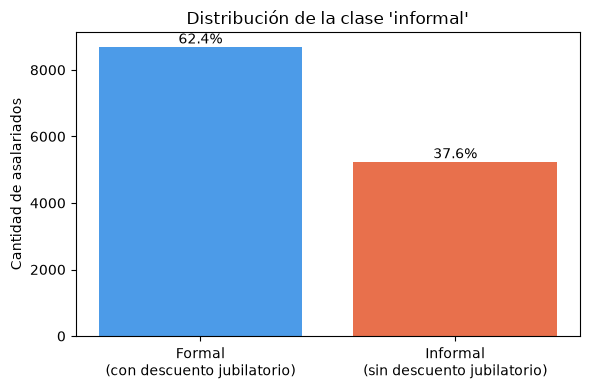


Clase mayoritaria: 'no' (62.4%). Clase minoritaria: 'si' (37.6%).
Por cada asalariado 'si' hay 1.66 asalariados 'no'.
Un modelo que siempre responda 'no' acertaría el 62.4% de las veces sin aprender nada (accuracy de referencia).


In [34]:
# Propósito: identificar la variable a modelar (la clase 'informal') y ver cómo se distribuye,
# para saber si las dos clases están balanceadas y cuál es la accuracy de referencia.
import matplotlib.pyplot as plt

conteo = df_eph["informal"].value_counts()
total = conteo.sum()
nombres = {"si": "Informal\n(sin descuento jubilatorio)", "no": "Formal\n(con descuento jubilatorio)"}

print("Variable a modelar: 'informal' (si = trabajo sin descuento jubilatorio, no = con descuento).")
print(f"Distribución de la clase en los {total:,} asalariados:".replace(",", "."))
for clase, cant in conteo.items():
    print(f"  - {clase}: {cant:,} asalariados ({cant / total:.1%})".replace(",", "."))

fig, ax = plt.subplots(figsize=(6, 4))
colores = ["#e8704c" if c == "si" else "#4c9be8" for c in conteo.index]
barras = ax.bar([nombres.get(c, c) for c in conteo.index], conteo.values, color=colores)
for barra, cant in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width() / 2, cant, f"{cant / total:.1%}", ha="center", va="bottom")
ax.set_ylabel("Cantidad de asalariados")
ax.set_title("Distribución de la clase 'informal'")
plt.tight_layout()
plt.show()

mayoritaria, minoritaria = conteo.idxmax(), conteo.idxmin()
razon = conteo.max() / conteo.min()
print(f"\nClase mayoritaria: '{mayoritaria}' ({conteo.max() / total:.1%}). "
      f"Clase minoritaria: '{minoritaria}' ({conteo.min() / total:.1%}).")
print(f"Por cada asalariado '{minoritaria}' hay {razon:.2f} asalariados '{mayoritaria}'.")
print(f"Un modelo que siempre responda '{mayoritaria}' acertaría el {conteo.max() / total:.1%} "
      f"de las veces sin aprender nada (accuracy de referencia).")

Podemos observar entonces que la variable a modelar (informal) tiene 2 valores posibles que se distribuyen con un 62.4% de los casos en 'si' y un 37.6% en 'no'. No lo consideraría un desbalance extremo, pero si considero que la clase está desbalanceada de manera moderada. Esto es si tomamos el 40% como límite de "casi balanceada", el cual en este caso se traspasa por poco.

Por lo tanto: la consideraría entre leve y moderadamente desbalanceada.Y esto tiene consecuencias en los pasos que sigue, ya que un árbol debe superar el 62.4% de precisión para aportar algo útil (de otra manera es lo mismo que el azar) (hay que considerar esto, ya que no usaremos el 50% típico para comparar con el azar). Además lo debemos tener en cuenta para cuando hagamos la división en conjunto de entrenamiento y prueba, para que estén correctamente estratificados.

### 3.c. Genere el árbol de decisión que permita modelar la variable objetivo utilizando como criterio la entropía. Defina una estrategia de hold-out con proporciones de 80% para entrenamiento y 20% para testeo. Evalúe el resultado obtenido.

El árbol necesita datos preparados antes de entrenar: las categóricas hay que codificarlas (se hace como en 2b) y los vacíos hay que tratarlos.

**¿el vacío dice algo sobre la clase?**

In [35]:
# Propósito: comprobar si que una columna esté vacía se asocia con la clase.
# Si la tasa de informalidad entre las filas vacías es distinta a la de las filas con dato,
# el vacío aporta información y conviene conservarlo (por ejemplo, como categoría 'sin dato').
from IPython.display import display

es_informal = df_eph["informal"] == "si"
global_pct = es_informal.mean() * 100

filas = []
for col in df_eph.columns[df_eph.isna().any()]:
    vacia = df_eph[col].isna()
    filas.append({"Columna": col,
                  "Filas vacías": int(vacia.sum()),
                  "% informal entre las vacías": round(es_informal[vacia].mean() * 100, 1),
                  "% informal entre las que tienen dato": round(es_informal[~vacia].mean() * 100, 1)})
res = pd.DataFrame(filas).set_index("Columna")
res["Diferencia (puntos)"] = (res["% informal entre las vacías"]
                              - res["% informal entre las que tienen dato"]).round(1)

print(f"Referencia: {global_pct:.1f}% de todos los asalariados son informales.")
display(res)

print("\nLectura:")
for col, f in res.iterrows():
    sentido = "más" if f["Diferencia (puntos)"] > 0 else "menos"
    print(f"  - {col}: las filas vacías son informales {abs(f['Diferencia (puntos)']):.1f} puntos "
          f"{sentido} seguido que las que tienen dato.")

sin_antig = df_eph[df_eph["antiguedad"].isna()]["rama"].value_counts(normalize=True).head(3) * 100
print("\nRamas de actividad más frecuentes entre las filas sin dato de antigüedad:")
for rama, pct in sin_antig.items():
    print(f"  - {rama}: {pct:.1f}% de esas filas")

Referencia: 37.6% de todos los asalariados son informales.


,Filas vacías,% informal entre las vacías,% informal entre las que tienen dato,Diferencia (puntos)
Columna,,,,
calificacion,16,43.8,37.6,6.2
tamanio_establecimiento,3869,50.4,32.7,17.7
lugar_trabajo,1314,79.3,33.3,46.0
antiguedad,1401,78.6,33.0,45.6
empleo_temporario,2314,84.0,28.4,55.6
horas_semanales,20,45.0,37.6,7.4
ingreso_mensual,2598,40.6,36.9,3.7



Lectura:
  - calificacion: las filas vacías son informales 6.2 puntos más seguido que las que tienen dato.
  - tamanio_establecimiento: las filas vacías son informales 17.7 puntos más seguido que las que tienen dato.
  - lugar_trabajo: las filas vacías son informales 46.0 puntos más seguido que las que tienen dato.
  - antiguedad: las filas vacías son informales 45.6 puntos más seguido que las que tienen dato.
  - empleo_temporario: las filas vacías son informales 55.6 puntos más seguido que las que tienen dato.
  - horas_semanales: las filas vacías son informales 7.4 puntos más seguido que las que tienen dato.
  - ingreso_mensual: las filas vacías son informales 3.7 puntos más seguido que las que tienen dato.

Ramas de actividad más frecuentes entre las filas sin dato de antigüedad:
  - Servicio doméstico: 93.8% de esas filas
  - Comercio: 0.9% de esas filas
  - Industria: 0.7% de esas filas


Los vacíos no parecen ser azar, en cuatro columnas (lugar_trabajo, antiguedad, empleo_temporario, tamanio_establecimiento) las filas vacías son informales mucho más seguido que las que tienen dato (se toma el 37.6% como referencia). Por lo que un vacío en esas columnas podría indicar algo sobre la clase de interés. Y descartar filas distorsionaría el dataset, haciendo que perdamos información.

In [36]:
# Propósito: separar, para cada columna con vacíos, cuántos corresponden a servicio doméstico
# (donde la pregunta no se hace) y cuántos al resto (probablemente no respuesta),
# y ver cuán informales son los vacíos del resto.
from IPython.display import display

es_informal = df_eph["informal"] == "si"
es_dom = df_eph["rama"] == "Servicio doméstico"

print(f"Filas de servicio doméstico: {es_dom.sum():,} ({es_dom.mean():.1%} del dataset); "
      f"{es_informal[es_dom].mean():.1%} son informales.".replace(",", "."))
print(f"Fuera del servicio doméstico: {es_informal[~es_dom].mean():.1%} son informales.")

filas = []
for col in df_eph.columns[df_eph.isna().any()]:
    vacia = df_eph[col].isna()
    resto = vacia & ~es_dom
    filas.append({"Columna": col,
                  "Filas vacías": int(vacia.sum()),
                  "Vacías de servicio doméstico": int((vacia & es_dom).sum()),
                  "Vacías del resto": int(resto.sum()),
                  "Serv. doméstico CON dato": int((es_dom & ~vacia).sum()),
                  "% informal en vacías del resto": round(es_informal[resto].mean() * 100, 1) if resto.any() else None})
display(pd.DataFrame(filas).set_index("Columna"))

Filas de servicio doméstico: 1.329 (9.5% del dataset); 79.3% son informales.
Fuera del servicio doméstico: 33.2% son informales.


,Filas vacías,Vacías de servicio doméstico,Vacías del resto,Serv. doméstico CON dato,% informal en vacías del resto
Columna,,,,,
calificacion,16,1,15,1328,40.0
tamanio_establecimiento,3869,1316,2553,13,35.5
lugar_trabajo,1314,1314,0,15,NaN
antiguedad,1401,1314,87,15,67.8
empleo_temporario,2314,1319,995,10,90.1
horas_semanales,20,1,19,1328,42.1
ingreso_mensual,2598,228,2370,1101,36.9


Estrategias frente a datos faltantes:
- lugar_trabajo (nominal): Categoría “Sin dato” y one-hot. Todo vacío es servicio doméstico.
- antiguedad (ordinal, 6 niveles): Códigos 1 a 6 en orden y 0 = sin dato. El árbol aísla el vacío con un corte en 0.5 y conserva el orden.
- tamanio_establecimiento (ordinal, 12 tramos): Códigos 1 a 12 y 0 = sin dato. Un tamaño no existe en servicio doméstico, y 2.553 vacíos del resto son no respuesta que casi no informa.
- empleo_temporario (binaria): Tres valores: no, si, sin dato (one-hot). El vacío informa mucho.
- ingreso_mensual (numérica): Mediana calculada solo con entrenamiento. Vacío casi sin información.
- calificacion, horas_semanales: Descartar esas filas. A lo sumo 36 de 13.938 (0.26 %).

La mediana se calcula luego de separar los datos entre entrenamiento y prueba ya que si se calculara con todos los datos, la mediana incluiría información de las filas de prueba, que el árbol no debe conocer (es una fuga de información, _data leakage_). Los valores constantes (0, “Sin dato”) no tienen este problema.

Antes de codificar hace falta conocer las etiquetas exactas, sobre todo el orden de nivel_educativo, antiguedad y calificacion.

In [37]:
# Propósito: listar las categorías de cada variable con su cantidad de filas y su porcentaje
# de informalidad. Sirve para conocer las etiquetas exactas (necesarias para codificar los
# ordinales en orden) y para ver qué categorías se asocian más con la informalidad.
from IPython.display import display

es_informal = df_eph["informal"] == "si"
columnas_cat = ["region", "sexo", "nivel_educativo", "sector", "rama", "calificacion",
                "lugar_trabajo", "antiguedad", "empleo_temporario", "tamanio_establecimiento"]

print(f"Referencia: {es_informal.mean():.1%} de todos los asalariados son informales.")
for col in columnas_cat:
    t = (df_eph.assign(es_informal=es_informal)
               .groupby(col, dropna=False)["es_informal"].agg(["size", "mean"]))
    t.columns = ["Filas", "% informal"]
    t["% informal"] = (t["% informal"] * 100).round(1)
    t = t.sort_values("Filas", ascending=False)
    t.index = ["(vacío)" if pd.isna(i) else i for i in t.index]
    print(f"\n{col}")
    display(t)

Referencia: 37.6% de todos los asalariados son informales.

region


,Filas,% informal
Pampeana,4126,37.2
Noroeste,3086,42.1
GBA,2326,36.3
Patagonia,1739,21.4
Cuyo,1332,48.1
Noreste,1329,41.4



sexo


,Filas,% informal
Varón,7383,36.0
Mujer,6555,39.5



nivel_educativo


,Filas,% informal
Secundario completo,4732,39.3
Superior completo,3631,14.4
Superior incompleto,1988,38.2
Secundario incompleto,1959,60.3
Primario completo,1334,55.1
Primario incompleto,265,63.0
Sin instrucción,29,62.1


... (10 outputs left out)


empleo_temporario


,Filas,% informal
no,10331,21.8
(vacío),2314,84.0
si,1293,81.3



tamanio_establecimiento


,Filas,% informal
(vacío),3869,50.4
6.0,1382,43.5
9.0,1374,10.5
8.0,1293,14.9
7.0,1251,23.9
12.0,876,11.9
10.0,822,9.0
2.0,701,81.7
3.0,662,74.5
11.0,593,6.9


Cómo se transforman los datos

- Ordinal: nivel_educativo, calificacion, antiguedad, tamanio_establecimiento. Un número que respeta el orden natural. Por ej: 0 = sin dato	antiguedad: “Menos de 1 mes” → 1, “Más de 5 años” → 6, vacío → 0.
- Nominal (sin orden): region, sector, rama, lugar_trabajo, empleo_temporario. Una columna 0/1 por categoría (one-hot). Los vacíos son la categoría “Sin dato”. Por ej:“Construcción” → rama_Construcción = 1 y las otras 14 columnas de rama = 0.
- Binaria: sexo. Una columna mujer (1 o 0).	
- Numérica: edad, horas_semanales, ingreso_mensual Sin cambios. Los vacíos de ingreso se completan con la mediana del entrenamiento.

In [38]:
# Propósito: preparar los datos para Scikit-Learn: (1) descartar las pocas filas con vacíos sin
# información, (2) codificar los ordinales respetando su orden (0 = sin dato) y
# (3) pasar las categóricas a columnas 0/1 (one-hot), con "Sin dato" como categoría propia.
datos = df_eph.copy()

n_antes = len(datos)
datos = datos.dropna(subset=["calificacion", "horas_semanales"])
descartadas = n_antes - len(datos)
print(f"Filas descartadas por vacíos en 'calificacion' u 'horas_semanales': {descartadas} "
      f"({descartadas / n_antes:.2%} del dataset). Quedan {len(datos):,} filas.".replace(",", "."))

orden = {
    "nivel_educativo": ["Sin instrucción", "Primario incompleto", "Primario completo",
                        "Secundario incompleto", "Secundario completo",
                        "Superior incompleto", "Superior completo"],
    "calificacion": ["No calificada", "Operativa", "Técnica", "Profesional"],
    "antiguedad": ["Menos de 1 mes", "1 a 3 meses", "3 a 6 meses", "6 a 12 meses",
                   "1 a 5 años", "Más de 5 años"],
}

X = pd.DataFrame(index=datos.index)
X["edad"] = datos["edad"]
X["horas_semanales"] = datos["horas_semanales"]
X["ingreso_mensual"] = datos["ingreso_mensual"]   # los vacíos se completan después de separar train y test
X["mujer"] = (datos["sexo"] == "Mujer").astype(int)

for col, niveles in orden.items():
    codigos = datos[col].map({nivel: i + 1 for i, nivel in enumerate(niveles)})
    sin_mapear = datos[col].notna() & codigos.isna()
    assert not sin_mapear.any(), f"Etiquetas sin mapear en '{col}': {datos.loc[sin_mapear, col].unique()}"
    X[col] = codigos.fillna(0).astype(int)
X["tamanio_establecimiento"] = datos["tamanio_establecimiento"].fillna(0).astype(int)

nominales = ["region", "sector", "rama", "lugar_trabajo", "empleo_temporario"]
categoricas = datos[nominales].fillna("Sin dato")
X = pd.concat([X, pd.get_dummies(categoricas, dtype=int)], axis=1)
y = datos["informal"]

print("\nTratamiento de cada variable:")
print("  - Numéricas: edad, horas_semanales, ingreso_mensual")
print("  - Sexo: columna 'mujer' (1 = mujer, 0 = varón)")
print("  - Ordinales con su orden natural (0 = sin dato): "
      "nivel_educativo, calificacion, antiguedad, tamanio_establecimiento")
for col in nominales:
    extra = " (incluye la categoría 'Sin dato')" if datos[col].isna().any() else ""
    print(f"  - {col}: {categoricas[col].nunique()} columnas 0/1{extra}")
print(f"\nAtributos finales: {X.shape[1]} columnas para {X.shape[0]:,} filas.".replace(",", "."))

Filas descartadas por vacíos en 'calificacion' u 'horas_semanales': 33 (0.24% del dataset). Quedan 13.905 filas.

Tratamiento de cada variable:
  - Numéricas: edad, horas_semanales, ingreso_mensual
  - Sexo: columna 'mujer' (1 = mujer, 0 = varón)
  - Ordinales con su orden natural (0 = sin dato): nivel_educativo, calificacion, antiguedad, tamanio_establecimiento
  - region: 6 columnas 0/1
  - sector: 3 columnas 0/1
  - rama: 15 columnas 0/1
  - lugar_trabajo: 10 columnas 0/1 (incluye la categoría 'Sin dato')
  - empleo_temporario: 3 columnas 0/1 (incluye la categoría 'Sin dato')

Atributos finales: 45 columnas para 13.905 filas.


In [39]:
# Propósito: separar entrenamiento (80%) y prueba (20%) manteniendo la proporción de informales,
# y recién después completar los vacíos de 'ingreso_mensual' con la mediana del entrenamiento
# (así el conjunto de prueba no influye en ningún valor que usa el árbol).
from sklearn.model_selection import train_test_split
from IPython.display import display

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

mediana = X_train["ingreso_mensual"].median()
vacios_tr = int(X_train["ingreso_mensual"].isna().sum())
vacios_te = int(X_test["ingreso_mensual"].isna().sum())
X_train = X_train.fillna({"ingreso_mensual": mediana})
X_test = X_test.fillna({"ingreso_mensual": mediana})

print(f"Mediana de 'ingreso_mensual' en entrenamiento: $ {mediana:,.0f}".replace(",", "."))
print(f"Vacíos completados con esa mediana: {vacios_tr} en entrenamiento y {vacios_te} en prueba.")

resumen = pd.DataFrame({
    "Filas": [len(y_train), len(y_test)],
    "% informal ('si')": [(y_train == "si").mean() * 100, (y_test == "si").mean() * 100],
    "Accuracy de referencia (%)": [y_train.value_counts(normalize=True).max() * 100,
                                   y_test.value_counts(normalize=True).max() * 100],
}, index=["Entrenamiento (80%)", "Prueba (20%)"]).round(1)
display(resumen)

Mediana de 'ingreso_mensual' en entrenamiento: $ 900.000
Vacíos completados con esa mediana: 2085 en entrenamiento y 493 en prueba.


,Filas,% informal ('si'),Accuracy de referencia (%)
Entrenamiento (80%),11124,37.6,62.4
Prueba (20%),2781,37.6,62.4


Árbol sin restricciones: profundidad 37. 1.580 hojas para 11.124 filas de entrenamiento.


,Entrenamiento,Prueba
Métrica (%),,
Accuracy,100.0,81.8
Recall de 'si',100.0,75.1
Precision de 'si',100.0,76.2
F1 de 'si',100.0,75.6


Accuracy de referencia en prueba (responder siempre 'no'): 62.4%.
Diferencia de accuracy entrenamiento - prueba: 18.2 puntos porcentuales.


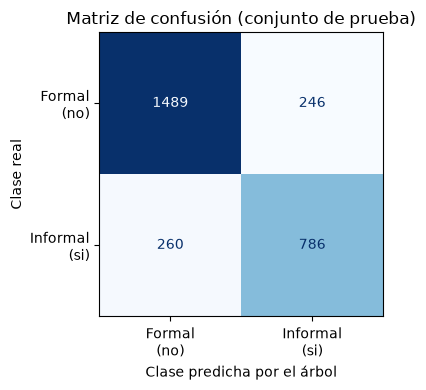

Informales reales: 1046. Detectados: 786 (75.1%). Clasificados como formales: 260 (24.9%).
Formales reales: 1735. Acertados: 1489 (85.8%). Clasificados como informales: 246 (14.2%).


In [40]:
# Propósito: entrenar el árbol de decisión con criterio de entropía y sin límites de tamaño,
# y evaluarlo en entrenamiento y prueba. La clase de interés es 'si' (informal).
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

modelo_eph = DecisionTreeClassifier(criterion="entropy", random_state=42)
modelo_eph.fit(X_train, y_train)
print(f"Árbol sin restricciones: profundidad {modelo_eph.get_depth()}, {modelo_eph.get_n_leaves():,} hojas "
      f"para {len(X_train):,} filas de entrenamiento.".replace(",", "."))

def metricas(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred) * 100,
            "Recall de 'si'": recall_score(y_real, y_pred, pos_label="si") * 100,
            "Precision de 'si'": precision_score(y_real, y_pred, pos_label="si") * 100,
            "F1 de 'si'": f1_score(y_real, y_pred, pos_label="si") * 100}

pred_train = modelo_eph.predict(X_train)
pred_test = modelo_eph.predict(X_test)
tabla = pd.DataFrame({"Entrenamiento": metricas(y_train, pred_train),
                      "Prueba": metricas(y_test, pred_test)}).round(1)
tabla.index.name = "Métrica (%)"
display(tabla)
print(f"Accuracy de referencia en prueba (responder siempre 'no'): {y_test.value_counts(normalize=True).max():.1%}.")
print(f"Diferencia de accuracy entrenamiento - prueba: "
      f"{tabla.loc['Accuracy', 'Entrenamiento'] - tabla.loc['Accuracy', 'Prueba']:.1f} puntos porcentuales.")

etiquetas = ["no", "si"]
cm = confusion_matrix(y_test, pred_test, labels=etiquetas)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Formal\n(no)", "Informal\n(si)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (conjunto de prueba)")
ax.set_xlabel("Clase predicha por el árbol")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

(formal_ok, formal_como_inf), (inf_como_formal, inf_ok) = cm
tot_inf, tot_formal = cm[1].sum(), cm[0].sum()
print(f"Informales reales: {tot_inf}. Detectados: {inf_ok} ({inf_ok / tot_inf:.1%}). "
      f"Clasificados como formales: {inf_como_formal} ({inf_como_formal / tot_inf:.1%}).")
print(f"Formales reales: {tot_formal}. Acertados: {formal_ok} ({formal_ok / tot_formal:.1%}). "
      f"Clasificados como informales: {formal_como_inf} ({formal_como_inf / tot_formal:.1%}).")

### Resultados
Como se documentó se imputaron los valores de 5 de las 7 variables que presentaban valores vacíos (_missing values_), calificacion y horas_semanales se descartan ya que representan el 0.36% de los datos totales (las tuplas que tienen valores faltantes en esas variables, no las variables en si), lo cual es muy poco para sacar conclusiones sobre si están relacionadas o no con la clase objetivo y no perdemos una cantidad de datos considerable ni de cerca.

Las variables ordinales, nominales y binarias se las codifica para que puedan ser usadas correctamente por el algoritmo.

Luego, al igual que en el punto 2, se separa en conjunto de entrenamiento 80% y test 20% y se construye el árbol. No me interesa detenerme demasiado en los resultados porque las conclusiones son iguales al punto 2. Al generar el árbol completo sin poda, este memoriza los datos de entrenamiento y no generaliza bien.

Esto se puede observar o intuir viendo la siguiente estadística: 'Árbol sin restricciones: profundidad 37. 1.580 hojas para 11.124 filas de entrenamiento.' ya que son 1.580 hojas para 11.124 filas, tendríamos 7 registros por cada hoja lo cual es poco para la escala del dataset y nos indica de manera intuitiva que el árbol está memorizando casos concretos del entrenamiento.

### 3.d. Ahora, evalúe diferentes combinaciones de valores para los parámetros:

      i. `max_depth`

      ii. `min_samples_split`

      iii. `min_samples_leaf`

      iv. `max_leaf_nodes`

      Realice al menos 10 corridas y tabule las configuraciones con los respectivos resultados.

| Parámetro | Qué limita | Ejemplo |
|---|---|---|
|max_depth | Cantidad máxima de preguntas encadenadas | Con 5, el árbol tiene como máximo 2⁵ = 32 hojas|
|min_samples_split | Mínimo de filas que debe tener un nodo para poder dividirse | Con 100, un nodo de 80 filas queda como hoja|
|min_samples_leaf | Mínimo de filas en cada hoja | Con 20, ninguna hoja tiene menos de 20 filas (hoy el promedio es 7)|
|max_leaf_nodes | Tope de hojas | Con 30, el árbol final tiene como máximo 30 hojas|


La consigna pide tabular las corridas con sus resultados, y la siguiente tabla los muestra en prueba para ver el efecto de cada parámetro. Es importante aclarar que la configuración final NO debe elegirse mirando la tabla, ya que si lo hacemos el conjunto de prueba dejaría de ser datos nuevos. Por lo que la elección se hace en 3e con validación cruzada, y la tabla siguiente es para comparar los efectos de cada hiperparámetro.

,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,Profundidad real,Hojas,Accuracy entrenamiento (%),Accuracy prueba (%),Brecha (puntos),Recall 'si' prueba (%),Precision 'si' prueba (%),F1 'si' prueba (%)
Corrida,,,,,,,,,,,,
1,sin límite,2,1,sin límite,37,1580,100.0,81.8,18.2,75.1,76.2,75.6
2,3,2,1,sin límite,3,8,81.6,84.3,-2.8,82.3,77.4,79.8
3,5,2,1,sin límite,5,32,83.5,85.3,-1.8,77.5,82.3,79.9
4,8,2,1,sin límite,8,180,86.6,84.5,2.0,75.5,82.0,78.6
5,12,2,1,sin límite,12,587,91.2,84.3,6.9,78.3,79.5,78.9
6,sin límite,20,1,sin límite,26,652,91.1,83.3,7.8,75.5,79.1,77.3
7,sin límite,100,1,sin límite,18,207,86.9,85.0,2.0,82.3,78.7,80.5
8,sin límite,2,5,sin límite,24,844,91.6,82.8,8.9,75.6,77.9,76.8
9,sin límite,2,20,sin límite,18,308,87.0,84.4,2.7,78.3,79.7,79.0


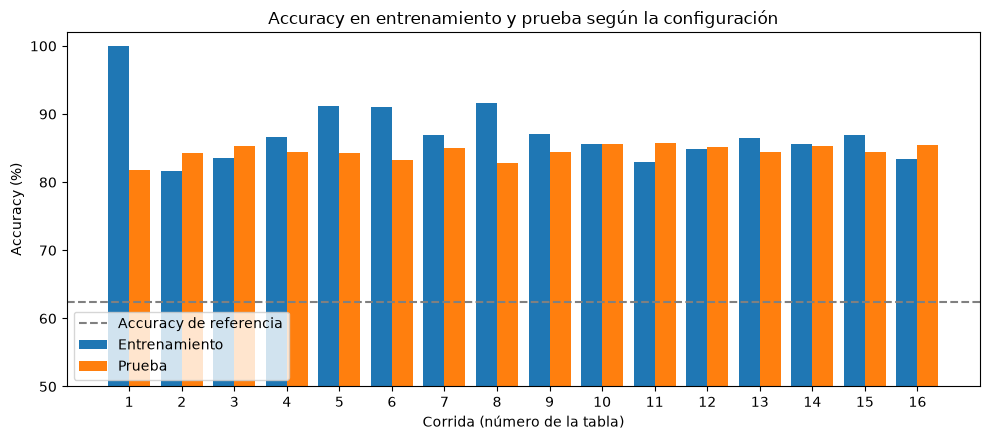

Se probaron 16 configuraciones.
Mayor accuracy en prueba: corrida 11 (85.7%), con 10 hojas.
Árbol sin límites (corrida 1): 81.8% en prueba y 18.2 puntos de brecha.


In [41]:
# Propósito: probar 16 configuraciones de hiperparámetros que limitan el crecimiento del árbol
# (max_depth, min_samples_split, min_samples_leaf, max_leaf_nodes) y ver cómo cambian el tamaño
# del árbol, su desempeño en entrenamiento y prueba, y la brecha entre ambos (sobreajuste).
# Los parámetros que no se mencionan quedan en su valor por defecto.
configuraciones = [
    {},                                                         # referencia: sin límites
    {"max_depth": 3}, {"max_depth": 5}, {"max_depth": 8}, {"max_depth": 12},
    {"min_samples_split": 20}, {"min_samples_split": 100},
    {"min_samples_leaf": 5}, {"min_samples_leaf": 20}, {"min_samples_leaf": 50},
    {"max_leaf_nodes": 10}, {"max_leaf_nodes": 30}, {"max_leaf_nodes": 100},
    {"max_depth": 8, "min_samples_leaf": 20},
    {"max_depth": 10, "min_samples_split": 50, "min_samples_leaf": 10},
    {"max_depth": 6, "min_samples_leaf": 30, "max_leaf_nodes": 20},
]

filas = []
for params in configuraciones:
    m = DecisionTreeClassifier(criterion="entropy", random_state=42, **params).fit(X_train, y_train)
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    acc_tr = accuracy_score(y_train, p_tr) * 100
    acc_te = accuracy_score(y_test, p_te) * 100
    filas.append({
        "max_depth": params.get("max_depth", "sin límite"),
        "min_samples_split": params.get("min_samples_split", 2),
        "min_samples_leaf": params.get("min_samples_leaf", 1),
        "max_leaf_nodes": params.get("max_leaf_nodes", "sin límite"),
        "Profundidad real": m.get_depth(),
        "Hojas": m.get_n_leaves(),
        "Accuracy entrenamiento (%)": acc_tr,
        "Accuracy prueba (%)": acc_te,
        "Brecha (puntos)": acc_tr - acc_te,
        "Recall 'si' prueba (%)": recall_score(y_test, p_te, pos_label="si") * 100,
        "Precision 'si' prueba (%)": precision_score(y_test, p_te, pos_label="si") * 100,
        "F1 'si' prueba (%)": f1_score(y_test, p_te, pos_label="si") * 100,
    })

corridas = pd.DataFrame(filas).round(1)
corridas.index = range(1, len(corridas) + 1)
corridas.index.name = "Corrida"
display(corridas)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(corridas))
ancho = 0.4
ax.bar(x - ancho / 2, corridas["Accuracy entrenamiento (%)"], ancho, label="Entrenamiento")
ax.bar(x + ancho / 2, corridas["Accuracy prueba (%)"], ancho, label="Prueba")
ax.axhline(y_test.value_counts(normalize=True).max() * 100, color="gray", linestyle="--",
           label="Accuracy de referencia")
ax.set_xticks(x)
ax.set_xticklabels(corridas.index)
ax.set_ylim(50, 102)
ax.set_xlabel("Corrida (número de la tabla)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy en entrenamiento y prueba según la configuración")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

mejor = corridas["Accuracy prueba (%)"].idxmax()
print(f"Se probaron {len(corridas)} configuraciones.")
print(f"Mayor accuracy en prueba: corrida {mejor} ({corridas.loc[mejor, 'Accuracy prueba (%)']}%), "
      f"con {corridas.loc[mejor, 'Hojas']} hojas.")
print(f"Árbol sin límites (corrida 1): {corridas.loc[1, 'Accuracy prueba (%)']}% en prueba y "
      f"{corridas.loc[1, 'Brecha (puntos)']} puntos de brecha.")

Hallazgos
- Simplificar siempre ayuda en prueba. Las 15 configuraciones con límite rinden entre 82.8 % y 85.7 %, contra 81.8 % del árbol sin límites: una mejora de +1.0 a +3.9 puntos. Contra la referencia de 62.4 %, la mejor suma +23.3 puntos.
- Hay una meseta. Entre 8 y 143 hojas la accuracy en prueba queda en 84.3–85.7 %. Los cinco primeros (corridas 11, 10, 16, 3 y 14) están entre 85.3 % y 85.7 %, una diferencia de 0.4 puntos, o sea ≈ 11 filas de 2.781. No hay un ganador claro.
- Un árbol de 10 hojas rinde igual que uno de 143 (85.7 % contra 85.6 %). Es 14 veces más chico y mucho más fácil de leer. Es la navaja de Occam de la teórica.
- max_depth reproduce la curva de la teórica. En entrenamiento la accuracy sube con la profundidad (81.6, 83.5, 86.6, 91.2, hasta 100 %). En prueba sube hasta profundidad 5 (85.3 %) y después baja (84.5, 84.3, 81.8). La brecha crece de −1.8 a 18.2: es el paso de subajuste a sobreajuste.
- Los límites suaves casi no cortan. min_samples_split = 20 y min_samples_leaf = 5 dejan 652 y 844 hojas, y el árbol sigue memorizando (brechas de 7.8 y 8.9 puntos). Funcionan los límites grandes: min_samples_leaf = 50 logra brecha 0.0.
- Combinar límites no mejora. Las corridas 14 a 16 (85.3, 84.5 y 85.5 %) no superan a un solo límite fuerte (corridas 10 y 11).
- F1 de si. Dentro de la meseta va de 79.6 % a 81.1 %. El mejor es la corrida 10 (min_samples_leaf = 50): recall 82.1 % y precision 80.1 %, las dos razonablemente altas a la vez.

### 3.e. Repita el experimento en d) agregando una validación cruzada con 5-folds.
Se aplica a los 11.124 pacientes de entrenamiento (el conjunto de prueba no se toca):

- Se reparten en 5 grupos de ≈ 2.225 filas (11.124 / 5 = 2.224.8).
- Se entrena con 4 grupos (≈ 8.899 filas) y se valida con el quinto. Se repite 5 veces rotando el grupo.
- Para cada una de las 16 configuraciones hay entonces 5 resultados, de los que se informa el promedio y el desvío (cuánto varía el resultado según qué filas toquen en cada grupo). Son 16 × 5 = 80 entrenamientos.

Nota: la mediana del ingreso se calculó con todo el entrenamiento, así que cada fold de validación influyó levemente en ese valor. Es un efecto mínimo, ya que es un solo número y afecta a un atributo.

,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,Hojas (promedio),Accuracy entrenamiento (%),Accuracy validación (%),Desvío de validación (±),Brecha (puntos),Recall 'si' validación (%),Precision 'si' validación (%),F1 'si' validación (%)
Corrida,,,,,,,,,,,,
1,sin límite,2,1,sin límite,1244.6,100.0,80.5,0.7,19.5,74.3,74.0,74.1
2,3,2,1,sin límite,8.0,82.3,81.8,1.0,0.5,72.3,78.1,75.0
3,5,2,1,sin límite,31.8,83.5,82.7,0.5,0.8,70.3,81.3,75.4
4,8,2,1,sin límite,159.4,86.6,83.7,0.4,2.9,77.2,79.0,78.1
5,12,2,1,sin límite,535.6,91.9,82.9,0.7,8.9,76.1,78.1,77.0
6,sin límite,20,1,sin límite,531.0,91.4,82.0,0.4,9.4,74.8,76.8,75.8
7,sin límite,100,1,sin límite,170.4,86.9,84.0,0.7,2.9,77.3,79.6,78.4
8,sin límite,2,5,sin límite,678.2,91.8,81.7,0.7,10.0,74.1,76.6,75.3
9,sin límite,2,20,sin límite,245.4,87.0,83.8,0.9,3.2,75.8,80.2,77.9


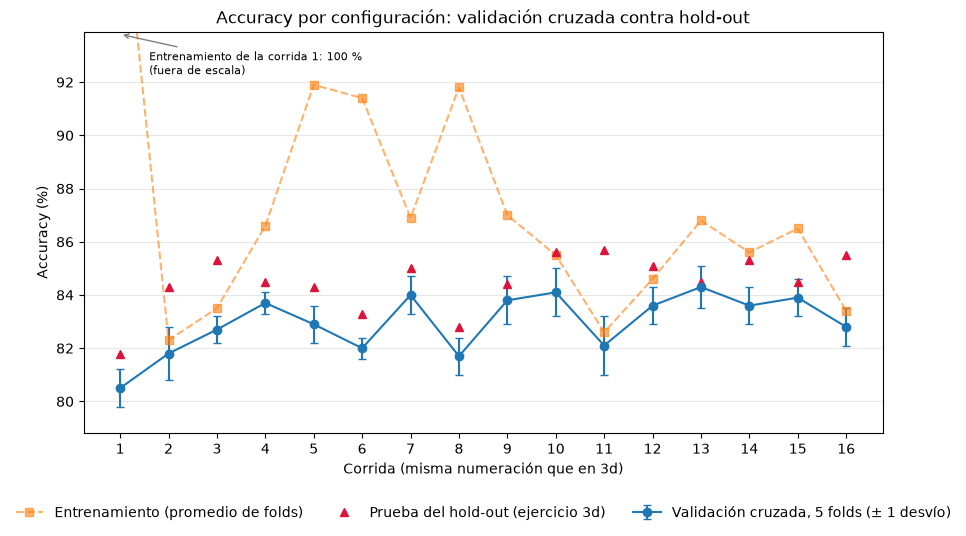

Mayor accuracy de validación: corrida 13 (84.3% ± 0.8).
Configuración más simple dentro de un desvío del mejor: corrida 12 (30.0 hojas en promedio, 83.6% de accuracy de validación).
En promedio, la accuracy en prueba (3d) supera a la de validación cruzada en 1.5 puntos.


In [43]:
# Propósito: repetir las 16 corridas de 3d con validación cruzada de 5 folds sobre el conjunto de
# entrenamiento. Se informa el promedio y el desvío entre folds, que es una estimación más estable
# que la de una sola partición. El conjunto de prueba no se usa en esta celda.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy",
           "recall": make_scorer(recall_score, pos_label="si"),
           "precision": make_scorer(precision_score, pos_label="si"),
           "f1": make_scorer(f1_score, pos_label="si")}

resultados = []
for params in configuraciones:
    m = DecisionTreeClassifier(criterion="entropy", random_state=42, **params)
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring,
                       return_train_score=True, return_estimator=True)
    resultados.append({
        "Hojas (promedio)": np.mean([e.get_n_leaves() for e in r["estimator"]]),
        "Accuracy entrenamiento (%)": r["train_accuracy"].mean() * 100,
        "Accuracy validación (%)": r["test_accuracy"].mean() * 100,
        "Desvío de validación (±)": r["test_accuracy"].std() * 100,
        "Brecha (puntos)": (r["train_accuracy"].mean() - r["test_accuracy"].mean()) * 100,
        "Recall 'si' validación (%)": r["test_recall"].mean() * 100,
        "Precision 'si' validación (%)": r["test_precision"].mean() * 100,
        "F1 'si' validación (%)": r["test_f1"].mean() * 100,
    })

parametros = corridas[["max_depth", "min_samples_split", "min_samples_leaf", "max_leaf_nodes"]].reset_index(drop=True)
cv_tabla = pd.concat([parametros, pd.DataFrame(resultados)], axis=1).round(1)
cv_tabla.index = range(1, len(cv_tabla) + 1)
cv_tabla.index.name = "Corrida"
display(cv_tabla)

# Propósito: redibujar el gráfico de 3e con la leyenda fuera del área de datos y con una escala
# que permita distinguir las corridas (el 100% de entrenamiento de la corrida 1 se marca aparte).
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(cv_tabla.index, cv_tabla["Accuracy validación (%)"], yerr=cv_tabla["Desvío de validación (±)"],
            fmt="o-", capsize=3, label="Validación cruzada, 5 folds (± 1 desvío)")
ax.plot(cv_tabla.index, cv_tabla["Accuracy entrenamiento (%)"], "s--", alpha=0.6,
        label="Entrenamiento (promedio de folds)")
ax.plot(corridas.index, corridas["Accuracy prueba (%)"], "^", color="crimson",
        label="Prueba del hold-out (ejercicio 3d)")

ymin = min((cv_tabla["Accuracy validación (%)"] - cv_tabla["Desvío de validación (±)"]).min(),
           corridas["Accuracy prueba (%)"].min()) - 1
ymax = cv_tabla["Accuracy entrenamiento (%)"].iloc[1:].max() + 2
ax.set_ylim(ymin, ymax)
ax.annotate("Entrenamiento de la corrida 1: 100 %\n(fuera de escala)", xy=(1, ymax - 0.1),
            xytext=(1.6, ymax - 1.6), fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))

ax.set_xticks(cv_tabla.index)
ax.set_xlabel("Corrida (misma numeración que en 3d)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy por configuración: validación cruzada contra hold-out")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

mejor = cv_tabla["Accuracy validación (%)"].idxmax()
umbral = cv_tabla.loc[mejor, "Accuracy validación (%)"] - cv_tabla.loc[mejor, "Desvío de validación (±)"]
simple = cv_tabla[cv_tabla["Accuracy validación (%)"] >= umbral]["Hojas (promedio)"].idxmin()
print(f"Mayor accuracy de validación: corrida {mejor} "
      f"({cv_tabla.loc[mejor, 'Accuracy validación (%)']}% ± {cv_tabla.loc[mejor, 'Desvío de validación (±)']}).")
print(f"Configuración más simple dentro de un desvío del mejor: corrida {simple} "
      f"({cv_tabla.loc[simple, 'Hojas (promedio)']} hojas en promedio, "
      f"{cv_tabla.loc[simple, 'Accuracy validación (%)']}% de accuracy de validación).")
dif = (corridas["Accuracy prueba (%)"].values - cv_tabla["Accuracy validación (%)"].values).mean()
print(f"En promedio, la accuracy en prueba (3d) supera a la de validación cruzada en {dif:.1f} puntos.")

,Árbol original (sin límites),Árbol final (max_leaf_nodes=30)
Hojas,1.580,30
Profundidad,37,8
Accuracy entrenamiento (%),100.0,84.9
Accuracy prueba (%),81.8,85.1
Brecha (puntos),18.2,-0.2
Recall 'si' prueba (%),75.1,77.0
Precision 'si' prueba (%),76.2,82.4
F1 'si' prueba (%),75.6,79.6


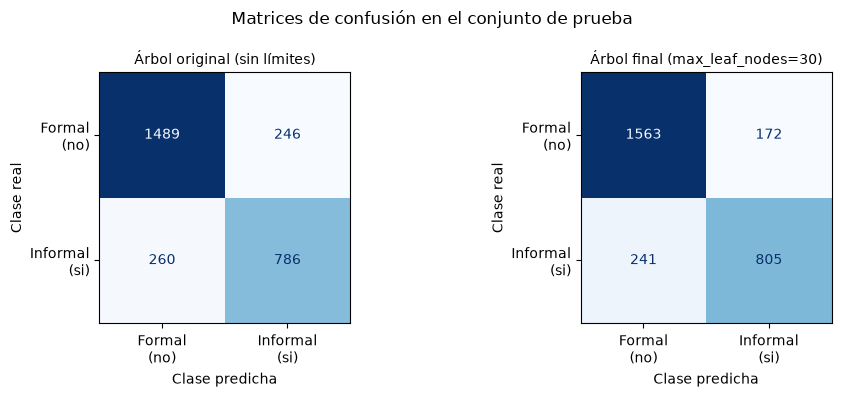

Informales reales en prueba: 1046.
Informales detectados:                 786 (original) -> 805 (final)
Informales clasificados como formales: 260 (original) -> 241 (final)
Formales clasificados como informales: 246 (original) -> 172 (final)
Errores totales:                       506 (original) -> 413 (final)


In [44]:
# Propósito: evaluar en el conjunto de prueba la configuración elegida con validación cruzada
# (max_leaf_nodes = 30) y compararla con el árbol original sin límites del punto 3c.
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

modelo_final_eph = DecisionTreeClassifier(criterion="entropy", max_leaf_nodes=30, random_state=42)
modelo_final_eph.fit(X_train, y_train)

modelos = {"Árbol original (sin límites)": modelo_eph,
           "Árbol final (max_leaf_nodes=30)": modelo_final_eph}
columnas = {}
for nombre, m in modelos.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    acc_tr = accuracy_score(y_train, p_tr) * 100
    acc_te = accuracy_score(y_test, p_te) * 100
    columnas[nombre] = {
        "Hojas": f"{m.get_n_leaves():,}".replace(",", "."),
        "Profundidad": str(m.get_depth()),
        "Accuracy entrenamiento (%)": f"{acc_tr:.1f}",
        "Accuracy prueba (%)": f"{acc_te:.1f}",
        "Brecha (puntos)": f"{acc_tr - acc_te:.1f}",
        "Recall 'si' prueba (%)": f"{recall_score(y_test, p_te, pos_label='si') * 100:.1f}",
        "Precision 'si' prueba (%)": f"{precision_score(y_test, p_te, pos_label='si') * 100:.1f}",
        "F1 'si' prueba (%)": f"{f1_score(y_test, p_te, pos_label='si') * 100:.1f}",
    }
display(pd.DataFrame(columnas))

etiquetas = ["no", "si"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cms = {}
for ax, (nombre, m) in zip(axes, modelos.items()):
    cms[nombre] = confusion_matrix(y_test, m.predict(X_test), labels=etiquetas)
    ConfusionMatrixDisplay(cms[nombre], display_labels=["Formal\n(no)", "Informal\n(si)"]
                           ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión en el conjunto de prueba")
plt.tight_layout()
plt.show()

(o_ok, o_fi), (o_if, o_ii) = cms["Árbol original (sin límites)"]
(f_ok, f_fi), (f_if, f_ii) = cms["Árbol final (max_leaf_nodes=30)"]
print(f"Informales reales en prueba: {f_if + f_ii}.")
print(f"Informales detectados:                 {o_ii} (original) -> {f_ii} (final)")
print(f"Informales clasificados como formales: {o_if} (original) -> {f_if} (final)")
print(f"Formales clasificados como informales: {o_fi} (original) -> {f_fi} (final)")
print(f"Errores totales:                       {o_if + o_fi} (original) -> {f_if + f_fi} (final)")

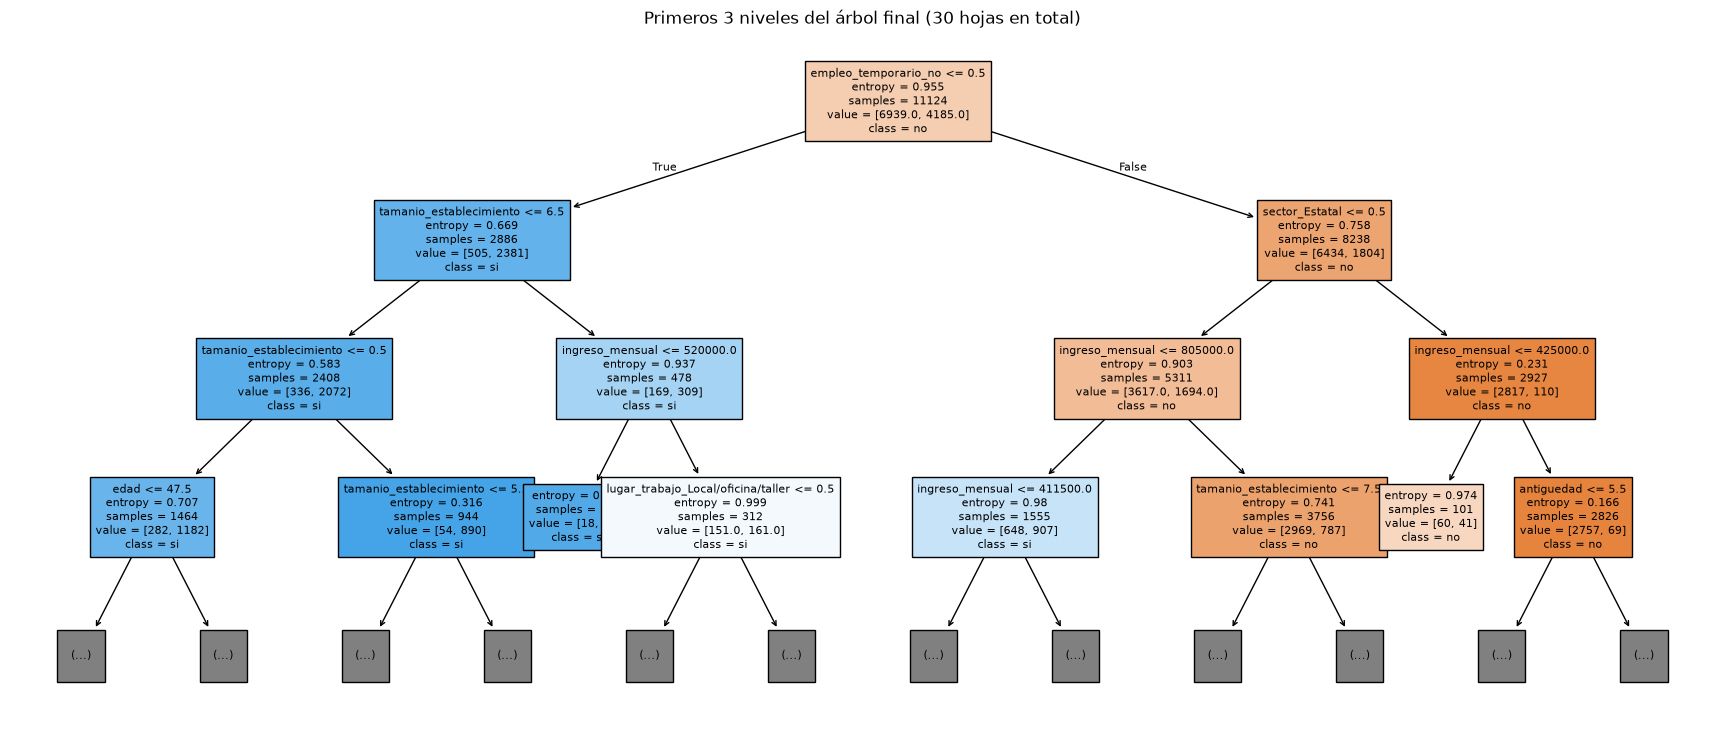

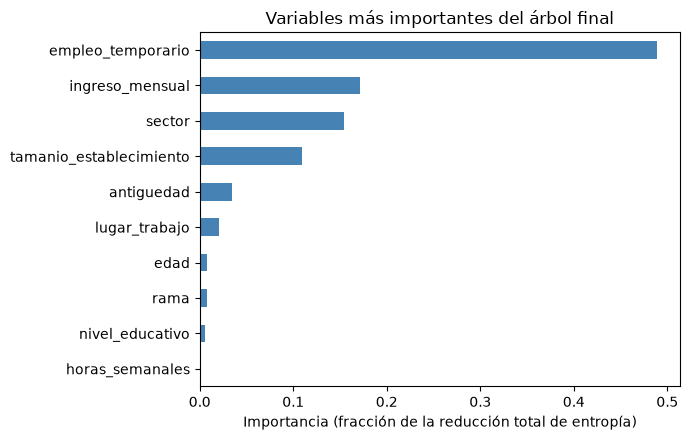

Las 3 variables más importantes (empleo_temporario, ingreso_mensual, sector) explican el 81.5% de la reducción de entropía.
Las 10 variables mostradas explican el 100.0%; las 3 restantes, el 0.0%.


In [45]:
# Propósito: ver cómo decide el árbol final y qué variables pesan más. Las columnas 0/1 que salen de
# una misma variable (por ejemplo, las 15 de 'rama') se suman para medir la importancia de la variable completa.
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(modelo_final_eph, feature_names=X.columns, class_names=list(modelo_final_eph.classes_),
          filled=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title(f"Primeros 3 niveles del árbol final ({modelo_final_eph.get_n_leaves()} hojas en total)")
plt.show()

def variable_original(col):
    for pref in ["region_", "sector_", "rama_", "lugar_trabajo_", "empleo_temporario_"]:
        if col.startswith(pref):
            return pref[:-1]
    return col

imp = (pd.Series(modelo_final_eph.feature_importances_, index=X.columns)
         .groupby(variable_original).sum().sort_values(ascending=False))
top = imp.head(10)

fig, ax = plt.subplots(figsize=(7, 4.5))
top[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Importancia (fracción de la reducción total de entropía)")
ax.set_title("Variables más importantes del árbol final")
plt.tight_layout()
plt.show()

print(f"Las 3 variables más importantes ({', '.join(top.index[:3])}) explican el "
      f"{top.iloc[:3].sum():.1%} de la reducción de entropía.")
print(f"Las 10 variables mostradas explican el {top.sum():.1%}; "
      f"las {len(imp) - 10} restantes, el {1 - top.sum():.1%}.")

### 3.f Conclusiones
Primero un repaso de lo que se hizo: se diagnosticaron los valores faltantes, se codificaron las variables nominales, ordinales y binarias, se imputaron los datos faltantes y se descartaron las tuplas con faltantes en 2 variables que representaban un porcenaje prescindible, además las medianas se calculan luego de dividir los datos en train y test para no generar un _data leakeage_. Luego se realizó un hold-out 80/20 **estratificado**, y se construyó el árbol sin límites (sin modificar los hiperparámetros). Luego se realizaron 16 corridas modificando los hiperparámetros y finalmente se realizó una validación cruzada de 5 folds.

En cuanto a los resultados obtenidos:

El árbol sin límites presentó una profundidad = 37 nodos, con 1580 hojas (7 registros por hoja aprox), y su desempeño fue de 100% en entrenamiento y 81.8% en test. Presentando un sobreajuste de 18.2%, por lo que podríamos decir que no generaliza bien, sino que memoriza los datos de entrenamiento.

Lo que podemos concluir de los parámetros (sumado a lo que vimos también en el punto 2) es que limitar el tamaño del árbol suele ser una buena idea. Los límites suaves casi no podan el árbol, mientras que los límites grandes eliminaron el sobreajuste. Sin embargo, esto puede ser específico de los dos casos tratados, pero lo que podemo extrapolar de estos dos casos es que si no realizamos una poda el árbol se genera completo y sobreajusta al entrenamiento, generalizando de manera pobre. Por lo que es una buena idea realizar una poda. La búsqueda de hiperparámetros es una tarea computacionalmente costosa pero dio buenos resultados y creo que vale la pena realizarla si queremos modelos de calidad que generalicen correctamente. 

Hold-out contra validación cruzada:

La estrategia de hold-out reporta mejor accuracy que la de validación cruzada en general para los mismos casos. Entiendo que esto puede deberse a que en hold-out se genera el arbol con los parámetros dados y se prueba directamente sobre los datos de prueba, por lo que hay más chances que el árbol generado "adivine" algunos casos, o se preste más a las coincidencias. En cambio la validación cruzada lo que hace es dividir el conjunto de entrenamiento y realizar 5 iteraciones turnando 1/5 de ese conjunto como datos para validar el arbol, reportando un promedio de los resultados obtenidos. Esto entiendo que disminuye la precisión en 1-3% pero me genera más confianza que el modelo elegido sea más capaz de generalizar. Más cuando **el _mejor_ modelo reportado por la estrategia de hold-out NO es el mismo que el de validación cruzada** (el mismo se refiere a la configuración de hiperparámetros elegida).

Con una sola partición, la corrida 11 parecía la mejor (85.7 %), y en validación cruzada es de las más bajas (82.1 %).

Elección: corrida 12 (max_leaf_nodes = 30), la más simple dentro de un desvío del mejor (que es la 13 según lo reportado por la validación cruzada).

Resultado final: 85.1 % de accuracy en prueba (83.6 % en validación cruzada), 30 hojas, brecha ≈ 0, F1 de si 79.6 %, con 413 errores contra 506.

Interpretación final observando el árbol obtenido: la informalidad está asociada a empleo temporario o sin dato, a tamaños de establecimiento chicos, a ingresos bajos y al sector privado, y casi ausente en empleo permanente del sector estatal.